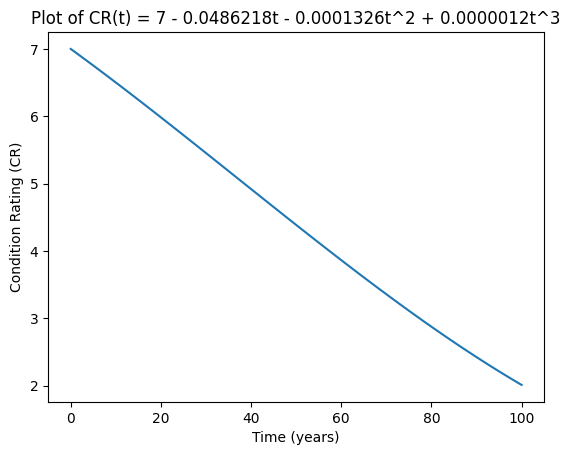

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def CR_function(t):
    """
    Returns the value of CR = 7 - 0.0486218t - 0.0001326t^2 + 0.0000012t^3
    for a given time (t).
    """
    return 7 - 0.0486218*t - 0.0001326*(t**2) + 0.0000012*(t**3)

# Define the time range for plotting
t_values = np.linspace(0, 100, 101)  # from 0 to 100 in steps of 1, e.g.

# Compute CR values at each t
CR_values = CR_function(t_values)

# Create the plot
plt.plot(t_values, CR_values)

# Label axes
plt.xlabel("Time (years)")
plt.ylabel("Condition Rating (CR)")

# Title (optional)
plt.title("Plot of CR(t) = 7 - 0.0486218t - 0.0001326t^2 + 0.0000012t^3")

# Display the figure
plt.show()


Assigning crack diffusivities: 100%|███████████████████████████████████████| 220000/220000 [00:00<00:00, 333621.69it/s]


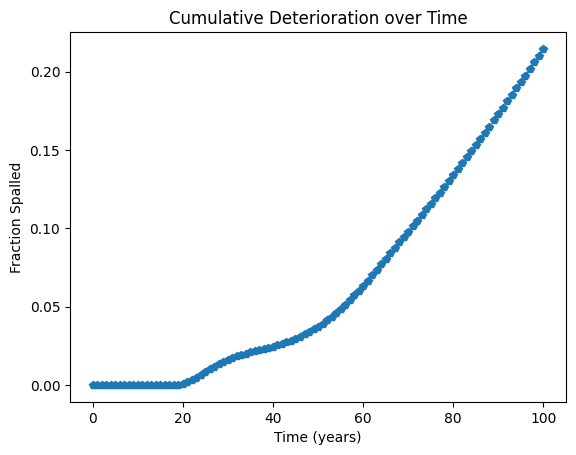

In [9]:
# -*- coding: cp1252 -*-
import numpy as np
import math, random
from scipy.stats import norm
from scipy import special
import matplotlib.pyplot as plt
from tqdm import tqdm

# -----------------------------
# USER-INPUT PARAMETERS
# -----------------------------

Cover_Mean = 2.0       # inches
Cover_Stdev = 0.1      # inches

Diffusivity_Mean = 0.0048   # in^2 / year
Diffusivity_Stdev = 0.002   # in^2 / year

ChlorideThreshold_Mean = 2.2761    # lbs/yd^3
ChlorideThreshold_Stdev = 0.22761  # lbs/yd^3

ChlorideSurfaceConcentration_Mean = 9.22   # lbs/yd^3
ChlorideSurfaceConcentration_Stdev = 3.08  # lbs/yd^3

PropegationTime_Mean = 6.0   # years
PropegationTime_Stdev = 4.0  # years

Nitrite_addition = 0         # 1 for nitrite, 0 for no nitrite
Nitrite_concentration = 10   # pcy
native_chloride = 0.1        # pcy
crack_fraction = 0.06
crack_diffusivity_ratio = 20
crack_diffusivity_stdev = 5

jacket_cost = 10000
jacket_replacement_time = 25  # jacket durability in years
discount_rate = 0.05          # interest - inflation
spalls_per_jacket = 3         # number of spalls before a jacket is required

steps = 220000                # total number of elements for Monte Carlo
time = 100                    # simulation horizon (years)

# Truncation bounds (lower, upper) for random draws: [cover, D, Ct, Cs, T, crack-ratio]
truncl = [1.1, 0.002, 1.0,  10.0, 10.0,  5.0]
trunch = [10., 0.1,   20.0, 60.0, 60.0, 20.0]

# Derating factors (optional geometry factor)
derating_factor = [0.6, 0.3]
fraction_derated = [0.4, 0.2]  # fraction of elements with these geometry factors

# Basic table of means & stdevs for our random variables:
# 1) cover, 2) diffusivity, 3) (Ct - native_chloride), 4) Cs, 5) Tprop
averagevalues = [
    Cover_Mean,
    Diffusivity_Mean,
    (ChlorideThreshold_Mean - native_chloride),
    ChlorideSurfaceConcentration_Mean,
    PropegationTime_Mean
]
StandardDeviations = [
    Cover_Stdev,
    Diffusivity_Stdev,
    ChlorideThreshold_Stdev,
    ChlorideSurfaceConcentration_Stdev,
    PropegationTime_Stdev
]


# -----------------------------
# PREP & HELPER FUNCTIONS
# -----------------------------

# Expand fraction_derated with leftover portion assigned factor=1
# This partitions the 'steps' into segments that apply different derating factors
fraction_sum = sum(fraction_derated)
fraction_derated.append(1 - fraction_sum)
derating_factor.append(1)

# Build cumulative array for derating
derating_cumsum = [0.0]
for i in range(len(derating_factor)):
    derating_cumsum.append(derating_cumsum[-1] + fraction_derated[i])

# Create array for the geometry derating factor for each simulated element
derating_array = []
for i in tqdm(range(steps), desc="Assigning geometry derating factors"):
    for j in range(len(derating_factor)):
        low_idx = int(derating_cumsum[j] * steps)
        high_idx = int(derating_cumsum[j+1] * steps)
        if low_idx <= i < high_idx:
            derating_array.append(derating_factor[j])
            break

# Create array for crack diffusivity ratio for each simulated element
crack_array = []
for i in tqdm(range(steps), desc="Assigning crack diffusivities"):
    done_flag = False
    while not done_flag:
        z = random.gauss(0, 1)
        candidate = crack_diffusivity_ratio + z * crack_diffusivity_stdev
        if truncl[5] < candidate < trunch[5]:
            crack_array.append(candidate)
            done_flag = True


# Define the function that calculates time to corrosion initiation + propagation
# For simplicity, we separate the Nitrite case (if Nitrite_addition==1)
if Nitrite_addition == 0:
    # => time = (cover^2)/(4*D*(erfinv(1 - Ct/Cs)^2)) + T_prop
    def time_to_failure(cover, diffusivity, Ct, Cs, Tprop, nitrite):
        # if c/d < 1 => standard formula
        ratio = Ct / Cs
        if ratio < 1:
            inv_val = special.erfinv(1 - ratio)
            # If the erfinv is valid, compute
            return cover**2 / (4.0 * diffusivity * (inv_val**2)) + Tprop
        # If the ratio >=1 => it never corrodes in this simplified approach
        return 1000  # effectively outside simulation horizon
else:
    # => time = (cover^2)/(4*D*(erfinv(1 - (f*(Cs - Ct)/(f+Cs)+Ct ) / Cs ))^2) + Tprop
    def time_to_failure(cover, diffusivity, Ct, Cs, Tprop, nitrite):
        # This formula is a placeholder from your snippet
        # that modifies threshold based on nitrite
        temp_ct = nitrite*(Cs - Ct)/(nitrite + Cs) + Ct
        ratio = temp_ct / Cs
        if ratio < 1:
            inv_val = special.erfinv(1 - ratio)
            return cover**2 / (4.0 * diffusivity * (inv_val**2)) + Tprop
        return 1000


# -----------------------------
# MONTE CARLO SIMULATION
# -----------------------------
# Build 2D array to hold random draws for each parameter
monte_in = [[0.0]*steps for _ in range(5)]

# Generate random draws for each parameter i across all elements j
for i in range(5):        # index for each of the 5 input parameters
    for j in range(steps):
        valid_flag = False
        while not valid_flag:
            z = random.gauss(0,1)
            candidate = z*StandardDeviations[i] + averagevalues[i]
            # If parameter is diffusivity
            # apply geometry derating factor or cracked ratio if i==1
            a = 1.0
            if i == 1:
                # geometry derating
                a /= derating_array[j]
                # cracked diffusivity
                if random.random() < crack_fraction:
                    a *= crack_array[j]
            candidate *= a

            # Check truncation constraints
            if truncl[i] < candidate < trunch[i]:
                monte_in[i][j] = candidate
                valid_flag = True

# Now compute time-to-failure for each simulated element
time_out = [0]*steps
for i in range(steps):
    cover = monte_in[0][i]
    D = monte_in[1][i]
    Ct = monte_in[2][i]
    Cs = monte_in[3][i]
    Tprop = monte_in[4][i]
    # Calculate time to spall (integer floor)
    val = time_to_failure(cover, D, Ct, Cs, Tprop, Nitrite_concentration)
    time_out[i] = math.floor(val)

# Count the distribution of failures by year (bins)
fail_counts = [0.0]*(time+1)
for i in range(steps):
    if 0 <= time_out[i] <= time:
        fail_counts[time_out[i]] += 1

# Convert fail_counts into cumulative fraction by year
fail_fraction = [fail_counts[0]/steps]
for yr in range(1, time+1):
    frac = fail_fraction[yr-1] + (fail_counts[yr]/steps)
    fail_fraction.append(frac)

# Create a time axis
time_axis = np.arange(time+1)

# -----------------------------
# PLOTTING
# -----------------------------
plt.plot(time_axis, fail_fraction, 'p--')
plt.xlabel('Time (years)')
plt.ylabel('Fraction Spalled')
plt.title('Cumulative Deterioration over Time')
plt.show()


In [11]:
 pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd

# Suppose these arrays already exist after running the simulation:
# time_axis     = 1D NumPy array or list of length N
# fail_fraction = 1D NumPy array or list of length N

# Create a dictionary to hold the columns for Excel
data = {
    'Time (years)': time_axis,
    'Spall Fraction': fail_fraction
}

# Convert dictionary to a pandas DataFrame
df = pd.DataFrame(data)

# Write directly to an Excel file
df.to_excel('spall_vs_time.xlsx', index=False)

print("Excel file 'spall_vs_time.xlsx' created successfully!")


Excel file 'spall_vs_time.xlsx' created successfully!


In [13]:
import os
print(os.getcwd())


C:\Users\Elniajo\Documents\Cluster Analysis


In [14]:
import numpy as np
import pandas as pd

def CR_function(t):
    """
    CR(t) = 7 - 0.0486218*t - 0.0001326*(t^2) + 0.0000012*(t^3)
    """
    return 7 - 0.0486218*t - 0.0001326*(t**2) + 0.0000012*(t**3)

# 1) Define a time array, e.g. 0..100 in integer steps
time_values = np.arange(0, 101, 1)

# 2) Compute CR(t) at each time step
CR_values = [CR_function(t) for t in time_values]

# 3) Build a pandas DataFrame
data = {
    'Time (years)': time_values,
    'Condition Rating': CR_values
}
df = pd.DataFrame(data)

# 4) Export to Excel
df.to_excel("CR_vs_time.xlsx", index=False)

print("Excel file 'CR_vs_time.xlsx' created successfully!")


Excel file 'CR_vs_time.xlsx' created successfully!


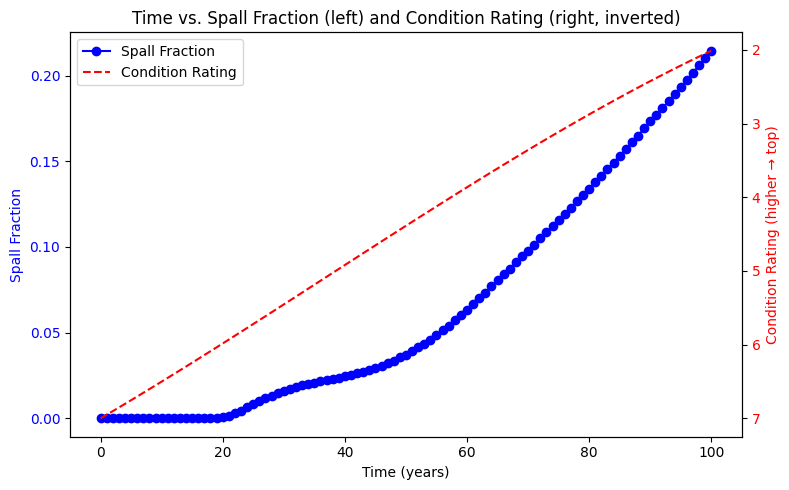

In [17]:
import matplotlib.pyplot as plt

# 1) Hard-code your data as Python lists (exactly from your table)
time_years = [
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
    10,11,12,13,14,15,16,17,18,19,
    20,21,22,23,24,25,26,27,28,29,
    30,31,32,33,34,35,36,37,38,39,
    40,41,42,43,44,45,46,47,48,49,
    50,51,52,53,54,55,56,57,58,59,
    60,61,62,63,64,65,66,67,68,69,
    70,71,72,73,74,75,76,77,78,79,
    80,81,82,83,84,85,86,87,88,89,
    90,91,92,93,94,95,96,97,98,99,
    100
]

spall_fraction = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    0, 0, 0, 0, 0, 0, 4.54545e-06, 1.36364e-05, 3.18182e-05, 0.000254545,
    0.000777273, 0.001604545, 0.002877273, 0.004481818, 0.00635, 0.008213636,
    0.010081818, 0.011695455, 0.013290909, 0.014804545, 0.016181818,
    0.017263636, 0.018277273, 0.019236364, 0.020040909, 0.02085, 0.021609091,
    0.022304545, 0.023004545, 0.023745455, 0.024436364, 0.025231818,
    0.026204545, 0.027290909, 0.028318182, 0.029445455, 0.030813636,
    0.032231818, 0.033722727, 0.0355, 0.037236364, 0.039177273, 0.041418182,
    0.043536364, 0.045904545, 0.048472727, 0.051295455, 0.054168182,
    0.057095455, 0.060222727, 0.06345, 0.066577273, 0.070145455, 0.073363636,
    0.076990909, 0.080509091, 0.084027273, 0.087354545, 0.090959091,
    0.094459091, 0.097827273, 0.101386364, 0.104936364, 0.1087, 0.112327273,
    0.115786364, 0.119254545, 0.122804545, 0.126595455, 0.130381818,
    0.134081818, 0.137836364, 0.141677273, 0.145481818, 0.149195455,
    0.153031818, 0.157077273, 0.161, 0.164945455, 0.169122727, 0.173195455,
    0.17705, 0.180995455, 0.185063636, 0.189231818, 0.19325, 0.197472727,
    0.201754545, 0.205890909, 0.210218182, 0.214495455
]

condition_rating = [
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616, 6.6031536, 6.552538, 6.501722, 6.4507128, 6.3995176,
    6.3481436, 6.296598, 6.244888, 6.1930208, 6.1410036, 6.0888436,
    6.036548, 5.984124, 5.9315788, 5.8789196, 5.8261536, 5.773288, 5.72033,
    5.6672868, 5.6141656, 5.5609736, 5.507718, 5.454406, 5.4010448,
    5.3476416, 5.2942036, 5.240738, 5.187252, 5.1337528, 5.0802476,
    5.0267436, 4.973248, 4.919768, 4.8663108, 4.8128836, 4.7594936,
    4.706148, 4.652854, 4.5996188, 4.5464496, 4.4933536, 4.440338,
    4.38741, 4.3345768, 4.2818456, 4.2292236, 4.176718, 4.124336,
    4.0720848, 4.0199716, 3.9680036, 3.916188, 3.864532, 3.8130428,
    3.7617276, 3.7105936, 3.659648, 3.608898, 3.5583508, 3.5080136,
    3.4578936, 3.407998, 3.358334, 3.3089088, 3.2597296, 3.2108036,
    3.162138, 3.11374, 3.0656168, 3.0177756, 2.9702236, 2.922968,
    2.876016, 2.8293748, 2.7830516, 2.7370536, 2.691388, 2.646062,
    2.6010828, 2.5564576, 2.5121936, 2.468298, 2.424778, 2.3816408,
    2.3388936, 2.2965436, 2.254598, 2.213064, 2.1719488, 2.1312596,
    2.0910036, 2.051188, 2.01182
]

# 2) Create a figure and a primary axis (ax1)
fig, ax1 = plt.subplots(figsize=(8,5))

# Plot the spall fraction (left y-axis)
color_left = 'blue'
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Spall Fraction", color=color_left)
ax1.plot(time_years, spall_fraction, color=color_left, marker='o', label="Spall Fraction")
ax1.tick_params(axis='y', labelcolor=color_left)

# 3) Create a twin axis for Condition Rating (ax2)
ax2 = ax1.twinx()
color_right = 'red'
ax2.set_ylabel("Condition Rating (higher → top)", color=color_right)
ax2.plot(time_years, condition_rating, color=color_right, linestyle='--', label="Condition Rating")
ax2.tick_params(axis='y', labelcolor=color_right)

# Invert the Condition Rating axis so that 7 is at the top and ~2 is at the bottom
ax2.invert_yaxis()  # simplest approach

# (Optionally, instead of invert_yaxis, you could do something like:
# ax2.set_ylim(7, 2)  # from 7 down to 2
# if you want explicit bounds.)

# 4) Make it look nice
plt.title("Time vs. Spall Fraction (left) and Condition Rating (right, inverted)")

# Optional: add legends.  We have two separate axes, so we can do:
lines_left, labels_left = ax1.get_legend_handles_labels()
lines_right, labels_right = ax2.get_legend_handles_labels()
ax1.legend(lines_left + lines_right, labels_left + labels_right, loc="upper left")

plt.tight_layout()
plt.show()


Observed rating transition times: {'CR=6': np.float64(20.0), 'CR=5': np.float64(39.0)}
Best scale factor =  1.0
Minimized cost =  301.12000000000006


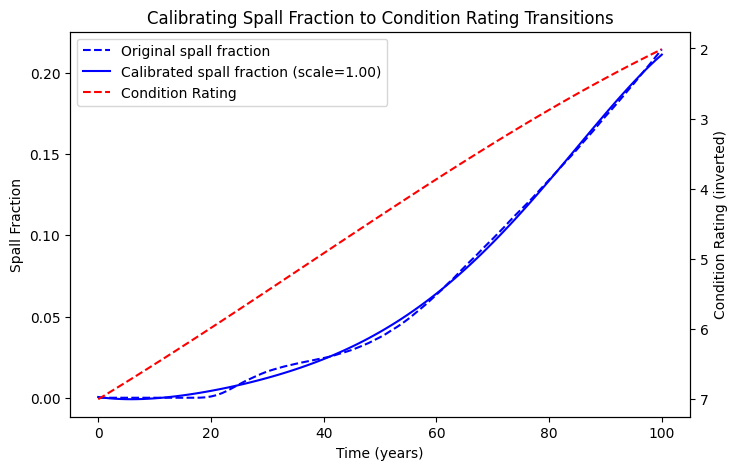

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# -------------------------------------------
# Step 1: Load your observed data
# -------------------------------------------
time_obs = np.array([
    0,1,2,3,4,5,6,7,8,9,
    10,11,12,13,14,15,16,17,18,19,
    20,21,22,23,24,25,26,27,28,29,
    30,31,32,33,34,35,36,37,38,39,
    40,41,42,43,44,45,46,47,48,49,
    50,51,52,53,54,55,56,57,58,59,
    60,61,62,63,64,65,66,67,68,69,
    70,71,72,73,74,75,76,77,78,79,
    80,81,82,83,84,85,86,87,88,89,
    90,91,92,93,94,95,96,97,98,99,
    100
], dtype=float)

spall_obs = np.array([
    # same array you have for spall fraction
    0,0,0,0,0,0,0,0,0,0,
    0,0,0,0,0,0,4.54545e-06,1.36364e-05,3.18182e-05,0.000254545,
    0.000777273,0.001604545,0.002877273,0.004481818,0.00635,0.008213636,
    0.010081818,0.011695455,0.013290909,0.014804545,0.016181818,
    0.017263636,0.018277273,0.019236364,0.020040909,0.02085,0.021609091,
    0.022304545,0.023004545,0.023745455,0.024436364,0.025231818,
    0.026204545,0.027290909,0.028318182,0.029445455,0.030813636,
    0.032231818,0.033722727,0.0355,0.037236364,0.039177273,0.041418182,
    0.043536364,0.045904545,0.048472727,0.051295455,0.054168182,
    0.057095455,0.060222727,0.06345,0.066577273,0.070145455,0.073363636,
    0.076990909,0.080509091,0.084027273,0.087354545,0.090959091,
    0.094459091,0.097827273,0.101386364,0.104936364,0.1087,0.112327273,
    0.115786364,0.119254545,0.122804545,0.126595455,0.130381818,
    0.134081818,0.137836364,0.141677273,0.145481818,0.149195455,
    0.153031818,0.157077273,0.161,0.164945455,0.169122727,0.173195455,
    0.17705,0.180995455,0.185063636,0.189231818,0.19325,0.197472727,
    0.201754545,0.205890909,0.210218182,0.214495455
], dtype=float)

rating_obs = np.array([
    # condition rating array
    7,6.9512468,6.9022356,6.8529736,6.803468,6.753726,6.7037548,
    6.6535616,6.6031536,6.552538,6.501722,6.4507128,6.3995176,
    6.3481436,6.296598,6.244888,6.1930208,6.1410036,6.0888436,
    6.036548,5.984124,5.9315788,5.8789196,5.8261536,5.773288,5.72033,
    5.6672868,5.6141656,5.5609736,5.507718,5.454406,5.4010448,
    5.3476416,5.2942036,5.240738,5.187252,5.1337528,5.0802476,
    5.0267436,4.973248,4.919768,4.8663108,4.8128836,4.7594936,
    4.706148,4.652854,4.5996188,4.5464496,4.4933536,4.440338,
    4.38741,4.3345768,4.2818456,4.2292236,4.176718,4.124336,
    4.0720848,4.0199716,3.9680036,3.916188,3.864532,3.8130428,
    3.7617276,3.7105936,3.659648,3.608898,3.5583508,3.5080136,
    3.4578936,3.407998,3.358334,3.3089088,3.2597296,3.2108036,
    3.162138,3.11374,3.0656168,3.0177756,2.9702236,2.922968,
    2.876016,2.8293748,2.7830516,2.7370536,2.691388,2.646062,
    2.6010828,2.5564576,2.5121936,2.468298,2.424778,2.3816408,
    2.3388936,2.2965436,2.254598,2.213064,2.1719488,2.1312596,
    2.0910036,2.051188,2.01182
], dtype=float)

# -------------------------------------------
# Step 2: Identify rating transition times
# -------------------------------------------
# For instance, define rating=6.0 as the drop from "Good" to "Satisfactory/Fair",
# rating=5.0 as the next threshold, and so on.
# We'll do a small function that finds the time when rating < threshold

def find_transition_time(time_array, rating_array, threshold):
    """
    Returns the first time in 'time_array' where rating_array < threshold.
    If rating never drops below threshold, return None or last time.
    """
    for t, r in zip(time_array, rating_array):
        if r < threshold:
            return t
    return None

# Let's define two transitions for demonstration:
rating_thresholds = {
    "CR=6": 6.0,
    "CR=5": 5.0,
}

observed_times = {}
for label, th in rating_thresholds.items():
    t_found = find_transition_time(time_obs, rating_obs, th)
    observed_times[label] = t_found

print("Observed rating transition times:", observed_times)
# e.g. might show { 'CR=6': 20.3, 'CR=5': 40.2 } etc.

# -------------------------------------------
# Step 3: Define spall thresholds for the same transitions
# -------------------------------------------
# Suppose we guess that crossing spall=0.01 means dropping below rating=6,
# crossing spall=0.05 means dropping below rating=5, etc.
spall_thresholds = {
    "CR=6": 0.01,
    "CR=5": 0.05,
}

# We'll define a function that finds the time the spall fraction crosses some threshold
def find_spall_time(time_array, spall_array, spall_th):
    for t, s in zip(time_array, spall_array):
        if s >= spall_th:
            return t
    return None

# -------------------------------------------
# Step 4: "Calibration" approach
# -------------------------------------------
# Let’s define a single parameter 'scale_time' that we apply to the time axis
# of spall_array. The idea is spall(t) actually becomes spall( scale_time * t ).
# We'll do a simple interpolation approach to get the "predicted" spall fraction at each real time.
# Then we find the times we cross spall thresholds, compare to observed rating transitions.

# For convenience, let's create an interpolation function for spall vs. scaled_time.
import numpy.polynomial.polynomial as poly

# We'll just do a polynomial fit to the spall data, so we can evaluate spall at any scaled_time.
coefs = poly.polyfit(time_obs, spall_obs, deg=5)  # 5th-degree polynomial approx

def spall_model(t):
    # returns spall fraction at time t using the polynomial approximation
    return poly.polyval(t, coefs)

def predicted_transition_times(scale, spall_threshold_dict):
    """
    Using the scale factor 'scale' on time,
    find the time at which spall crosses each threshold in spall_threshold_dict.
    We'll do a simple iterative approach or a small root-finding approach.
    """
    results = {}
    # For each threshold, we want to solve spall_model(scale * T) = threshold
    # We'll do a brute force or a small search over T in [0,1000], for demonstration.
    t_range = np.linspace(0, 120, 601)  # 0..120 in steps of 0.2 years
    for label, s_th in spall_threshold_dict.items():
        crossing_time = None
        for T_test in t_range:
            s_val = spall_model(scale * T_test)
            if s_val >= s_th:
                crossing_time = T_test
                break
        results[label] = crossing_time
    return results

# We'll define a cost function that sums squared differences between
# predicted transition times and observed rating transition times.
def cost_function(params):
    scale_time = params[0]
    # predicted times for each threshold
    pred_times = predicted_transition_times(scale_time, spall_thresholds)
    # sum of squared differences
    total_error = 0.0
    for label in rating_thresholds:
        t_obs = observed_times[label]
        t_pred = pred_times[label]
        if (t_obs is not None) and (t_pred is not None):
            total_error += (t_obs - t_pred)**2
        else:
            # if one side is None, we can add a large penalty
            total_error += 1000
    return total_error

# We'll do a quick optimization to find 'scale_time' that best aligns these transitions
res = minimize(cost_function, x0=[1.0], bounds=[(0.2,5.0)]) # guess range
best_scale = res.x[0]
print("Best scale factor = ", best_scale)
print("Minimized cost = ", res.fun)

# -------------------------------------------
# Step 5: Visual check
# -------------------------------------------
# We now have a best scale factor for time. We'll create a "calibrated" spall curve
# that we can compare directly to the observed rating transitions.

cal_time = time_obs
cal_spall = [spall_model(best_scale * t) for t in cal_time]

# We'll plot both the observed spall fraction (raw) and the calibrated spall fraction.
plt.figure(figsize=(8,5))
plt.plot(time_obs, spall_obs, 'b--', label="Original spall fraction")
plt.plot(cal_time, cal_spall, 'b-', label=f"Calibrated spall fraction (scale={best_scale:.2f})")

# Plot the rating on a second axis
ax1 = plt.gca()
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Spall Fraction")
ax2 = ax1.twinx()
ax2.plot(time_obs, rating_obs, 'r--', label="Condition Rating")
ax2.invert_yaxis()
ax2.set_ylabel("Condition Rating (inverted)")

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Calibrating Spall Fraction to Condition Rating Transitions")
plt.show()


In [20]:
def spall_to_rating(spall_fraction):
    """
    Returns an integer or float rating (0-9) based on
    spall fraction thresholds from the example mapping.
    Adjust thresholds as needed.
    """
    if spall_fraction < 0.01:          # <1%
        return 8.5  # between 9 and 8
    elif spall_fraction < 0.03:        # 1%–3%
        return 6.5  # between 7 and 6
    elif spall_fraction < 0.10:        # 3%–10%
        return 5
    elif spall_fraction < 0.25:        # 10%–25%
        return 4
    elif spall_fraction < 0.50:        # 25%–50%
        return 2.5  # between 3 and 2
    else:                              # >50%
        return 1  # ~ imminent failure


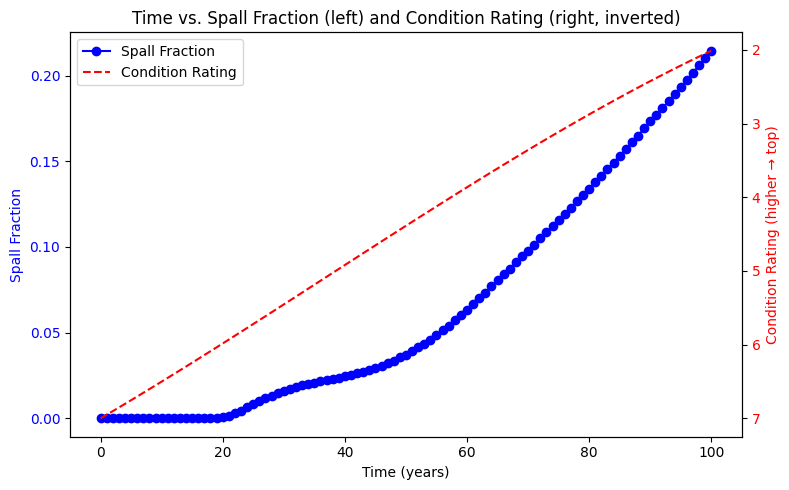

In [22]:
import matplotlib.pyplot as plt

# 1) Hard-code your data as Python lists (exactly from your table)
time_years = [
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
    10,11,12,13,14,15,16,17,18,19,
    20,21,22,23,24,25,26,27,28,29,
    30,31,32,33,34,35,36,37,38,39,
    40,41,42,43,44,45,46,47,48,49,
    50,51,52,53,54,55,56,57,58,59,
    60,61,62,63,64,65,66,67,68,69,
    70,71,72,73,74,75,76,77,78,79,
    80,81,82,83,84,85,86,87,88,89,
    90,91,92,93,94,95,96,97,98,99,
    100
]

spall_fraction = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    0, 0, 0, 0, 0, 0, 4.54545e-06, 1.36364e-05, 3.18182e-05, 0.000254545,
    0.000777273, 0.001604545, 0.002877273, 0.004481818, 0.00635, 0.008213636,
    0.010081818, 0.011695455, 0.013290909, 0.014804545, 0.016181818,
    0.017263636, 0.018277273, 0.019236364, 0.020040909, 0.02085, 0.021609091,
    0.022304545, 0.023004545, 0.023745455, 0.024436364, 0.025231818,
    0.026204545, 0.027290909, 0.028318182, 0.029445455, 0.030813636,
    0.032231818, 0.033722727, 0.0355, 0.037236364, 0.039177273, 0.041418182,
    0.043536364, 0.045904545, 0.048472727, 0.051295455, 0.054168182,
    0.057095455, 0.060222727, 0.06345, 0.066577273, 0.070145455, 0.073363636,
    0.076990909, 0.080509091, 0.084027273, 0.087354545, 0.090959091,
    0.094459091, 0.097827273, 0.101386364, 0.104936364, 0.1087, 0.112327273,
    0.115786364, 0.119254545, 0.122804545, 0.126595455, 0.130381818,
    0.134081818, 0.137836364, 0.141677273, 0.145481818, 0.149195455,
    0.153031818, 0.157077273, 0.161, 0.164945455, 0.169122727, 0.173195455,
    0.17705, 0.180995455, 0.185063636, 0.189231818, 0.19325, 0.197472727,
    0.201754545, 0.205890909, 0.210218182, 0.214495455
]

condition_rating = [
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616,6.6031536,6.552538, 6.501722,6.4507128,6.3995176,6.3481436,
    6.296598,6.244888,6.1930208,6.1410036,6.0888436,6.036548,5.984124,
    5.9315788,5.8789196,5.8261536,5.773288,5.72033,5.6672868,5.6141656,
    5.5609736,5.507718,5.454406,5.4010448,5.3476416,5.2942036,5.240738,
    5.187252,5.1337528,5.0802476,5.0267436,4.973248,4.919768,4.8663108,
    4.8128836,4.7594936,4.706148,4.652854,4.5996188,4.5464496,4.4933536,
    4.440338,4.38741,4.3345768,4.2818456,4.2292236,4.176718,4.124336,
    4.0720848,4.0199716,3.9680036,3.916188,3.864532,3.8130428,3.7617276,
    3.7105936,3.659648,3.608898,3.5583508,3.5080136,3.4578936,3.407998,
    3.358334,3.3089088,3.2597296,3.2108036,3.162138,3.11374,3.0656168,
    3.0177756,2.9702236,2.922968,2.876016,2.8293748,2.7830516,2.7370536,
    2.691388,2.646062,2.6010828,2.5564576,2.5121936,2.468298,2.424778,
    2.3816408,2.3388936,2.2965436,2.254598,2.213064,2.1719488,2.1312596,
    2.0910036,2.051188,2.01182
]

# 2) Create a figure and a primary axis (ax1)
fig, ax1 = plt.subplots(figsize=(8,5))

# Plot the spall fraction (left y-axis)
color_left = 'blue'
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Spall Fraction", color=color_left)
ax1.plot(time_years, spall_fraction, color=color_left, marker='o', label="Spall Fraction")
ax1.tick_params(axis='y', labelcolor=color_left)

# 3) Create a twin axis for Condition Rating (ax2)
ax2 = ax1.twinx()
color_right = 'red'
ax2.set_ylabel("Condition Rating (higher → top)", color=color_right)
ax2.plot(time_years, condition_rating, color=color_right, linestyle='--', label="Condition Rating")
ax2.tick_params(axis='y', labelcolor=color_right)

# Invert the Condition Rating axis so that 7 is at the top and ~2 is at the bottom
ax2.invert_yaxis()

# 4) Make it look nice
plt.title("Time vs. Spall Fraction (left) and Condition Rating (right, inverted)")

# Optional: add legends.  We have two separate axes, so we can do:
lines_left, labels_left = ax1.get_legend_handles_labels()
lines_right, labels_right = ax2.get_legend_handles_labels()
ax1.legend(lines_left + lines_right, labels_left + labels_right, loc="upper left")

plt.tight_layout()
plt.show()


In [23]:
# 1) We'll polynomial-fit the spall fraction data, or we can do direct interpolation.
from numpy.polynomial import Polynomial
spall_poly = Polynomial.fit(time_years, spall_fraction, deg=5)  # polynomial approximation

def spall_model(time, alpha):
    # Evaluate the spall fraction at scaled_time = alpha * time
    return spall_poly(alpha * time)

def predicted_rating(time, alpha):
    # Convert spall fraction -> rating using the user-defined threshold function
    s = spall_model(time, alpha)
    return spall_to_rating(s)

# We'll define a cost function comparing predicted rating vs. observed rating
def cost_function(params):
    alpha = params[0]
    # Evaluate rating mismatch across all time points
    mismatch = 0.0
    for i, t in enumerate(time_years):
        r_pred = predicted_rating(t, alpha)
        r_obs  = condition_rating[i]
        mismatch += (r_pred - r_obs)**2
    return mismatch

# We do a simple minimization approach
from scipy.optimize import minimize

res = minimize(cost_function, x0=[1.0], bounds=[(0.1, 10.0)])
best_alpha = res.x[0]
print("Best alpha:", best_alpha)
print("Final cost:", res.fun)


Best alpha: 1.0
Final cost: 263.86481705385137


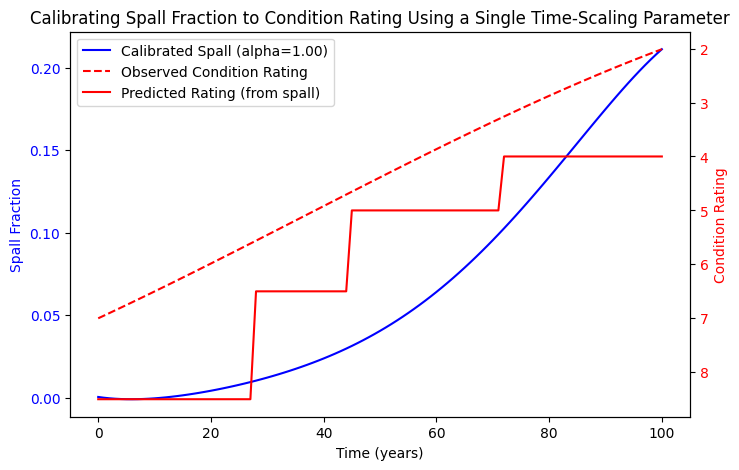

In [24]:
# Prepare data for plotting
calibrated_spall = [spall_model(t, best_alpha) for t in time_years]
pred_rating      = [spall_to_rating(s) for s in calibrated_spall]

fig, ax1 = plt.subplots(figsize=(8,5))

# Plot the calibrated spall fraction vs. time
ax1.plot(time_years, calibrated_spall, 'b-', label=f"Calibrated Spall (alpha={best_alpha:.2f})")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Spall Fraction", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot condition rating on a twin axis
ax2 = ax1.twinx()
ax2.plot(time_years, condition_rating, 'r--', label="Observed Condition Rating")
ax2.plot(time_years, pred_rating,      'r-', label="Predicted Rating (from spall)")
ax2.invert_yaxis()
ax2.set_ylabel("Condition Rating", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Calibrating Spall Fraction to Condition Rating Using a Single Time-Scaling Parameter")
plt.show()


Best alpha = 1.0
Cost = 12396.16


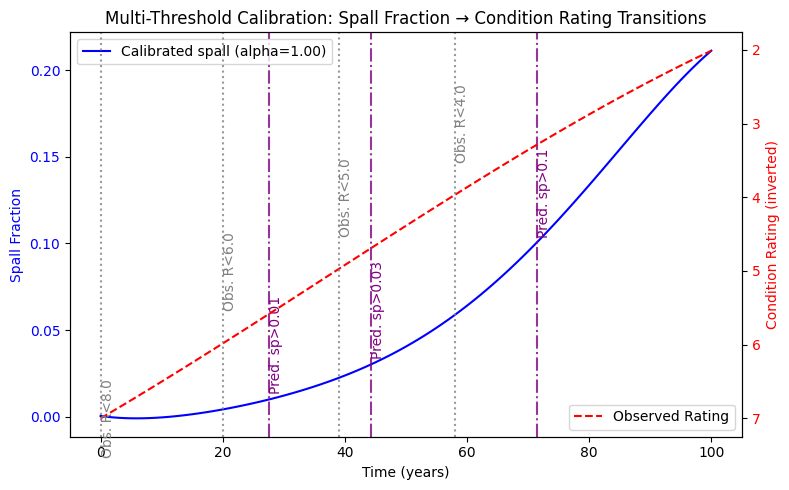

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# -------------------------------
# 1) OBSERVED DATA
# -------------------------------
time_years = np.array([
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
    10,11,12,13,14,15,16,17,18,19,
    20,21,22,23,24,25,26,27,28,29,
    30,31,32,33,34,35,36,37,38,39,
    40,41,42,43,44,45,46,47,48,49,
    50,51,52,53,54,55,56,57,58,59,
    60,61,62,63,64,65,66,67,68,69,
    70,71,72,73,74,75,76,77,78,79,
    80,81,82,83,84,85,86,87,88,89,
    90,91,92,93,94,95,96,97,98,99,
    100
], dtype=float)

condition_rating = np.array([
    # (Same as your code)
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616,6.6031536,6.552538, 6.501722,6.4507128,6.3995176,6.3481436,
    6.296598,6.244888,6.1930208,6.1410036,6.0888436,6.036548,5.984124,
    5.9315788,5.8789196,5.8261536,5.773288,5.72033,5.6672868,5.6141656,
    5.5609736,5.507718,5.454406,5.4010448,5.3476416,5.2942036,5.240738,
    5.187252,5.1337528,5.0802476,5.0267436,4.973248,4.919768,4.8663108,
    4.8128836,4.7594936,4.706148,4.652854,4.5996188,4.5464496,4.4933536,
    4.440338,4.38741,4.3345768,4.2818456,4.2292236,4.176718,4.124336,
    4.0720848,4.0199716,3.9680036,3.916188,3.864532,3.8130428,3.7617276,
    3.7105936,3.659648,3.608898,3.5583508,3.5080136,3.4578936,3.407998,
    3.358334,3.3089088,3.2597296,3.2108036,3.162138,3.11374,3.0656168,
    3.0177756,2.9702236,2.922968,2.876016,2.8293748,2.7830516,2.7370536,
    2.691388,2.646062,2.6010828,2.5564576,2.5121936,2.468298,2.424778,
    2.3816408,2.3388936,2.2965436,2.254598,2.213064,2.1719488,2.1312596,
    2.0910036,2.051188,2.01182
], dtype=float)

time_spall = time_years.copy()  # same time array
spall_fraction = np.array([
    # (Ensure no leading-zero issues!)
    0,0,0,0,0,0,0,0,0,0,
    0,0,0,0,0,0,4.54545e-06,1.36364e-05,3.18182e-05,0.000254545,
    0.000777273,0.001604545,0.002877273,0.004481818,0.00635,0.008213636,
    0.010081818,0.011695455,0.013290909,0.014804545,0.016181818,
    0.017263636,0.018277273,0.019236364,0.020040909,0.02085,0.021609091,
    0.022304545,0.023004545,0.023745455,0.024436364,0.025231818,
    0.026204545,0.027290909,0.028318182,0.029445455,0.030813636,
    0.032231818,0.033722727,0.0355,0.037236364,0.039177273,0.041418182,
    0.043536364,0.045904545,0.048472727,0.051295455,0.054168182,
    0.057095455,0.060222727,0.06345,0.066577273,0.070145455,0.073363636,
    0.076990909,0.080509091,0.084027273,0.087354545,0.090959091,
    0.094459091,0.097827273,0.101386364,0.104936364,0.1087,0.112327273,
    0.115786364,0.119254545,0.122804545,0.126595455,0.130381818,
    0.134081818,0.137836364,0.141677273,0.145481818,0.149195455,
    0.153031818,0.157077273,0.161,0.164945455,0.169122727,0.173195455,
    0.17705,0.180995455,0.185063636,0.189231818,0.19325,0.197472727,
    0.201754545,0.205890909,0.210218182,0.214495455
], dtype=float)

# -------------------------------
# 2) DEFINE RATING vs. SPALL THRESHOLDS
# -------------------------------
# We'll choose a few rating boundaries and matching spall thresholds:
# e.g., rating=8 -> spall=0.01, rating=6-> spall=0.03, rating=5-> spall=0.10, rating=4-> spall=0.25

rating_boundaries = [8.0, 6.0, 5.0, 4.0]
spall_thresholds  = [0.01, 0.03, 0.10, 0.25]

assert len(rating_boundaries) == len(spall_thresholds)

def find_rating_drop_time(t_array, r_array, boundary):
    """
    Return the earliest time 't' at which condition rating falls below 'boundary'.
    If rating never falls below that boundary, return None.
    """
    for t, r in zip(t_array, r_array):
        if r < boundary:
            return t
    return None

def find_spall_cross_time(t_array, s_array, threshold):
    """
    Return the earliest time 't' at which spall fraction >= threshold.
    If spall never crosses that threshold, return None.
    """
    for t, s in zip(t_array, s_array):
        if s >= threshold:
            return t
    return None

# Observed drop times for each rating boundary
observed_times = []
for rb in rating_boundaries:
    t_drop = find_rating_drop_time(time_years, condition_rating, rb)
    observed_times.append(t_drop)

# We'll do a polynomial fit of the spall fraction data for continuous evaluation
from numpy.polynomial import Polynomial
spall_poly = Polynomial.fit(time_spall, spall_fraction, deg=5)  # or deg=4/6

def spall_func(t, alpha):
    """
    Evaluate spall fraction at scaled time alpha*t using the polynomial approximation.
    """
    scaled_t = alpha * t
    return spall_poly(scaled_t)

def spall_cross_time(threshold, alpha):
    """
    Find the earliest time t in [0..120] where spall_func(t, alpha) >= threshold.
    (i.e. spall crosses 'threshold')
    """
    t_candidates = np.linspace(0,120,601)  # check every 0.2 years
    for T in t_candidates:
        if spall_func(T, alpha) >= threshold:
            return T
    return None

def cost_function(params):
    alpha = params[0]
    # For each boundary-threshold pair, find predicted crossing time and compare
    pred_times = []
    for thr in spall_thresholds:
        t_pred = spall_cross_time(thr, alpha)
        pred_times.append(t_pred)
    
    # sum of squared differences
    total_err = 0.0
    for (to, tp) in zip(observed_times, pred_times):
        if to is not None and tp is not None:
            total_err += (to - tp)**2
        else:
            # heavy penalty if we can't find crossing
            total_err += 9999
    return total_err

# -------------------------------
# 3) Optimize
# -------------------------------
from scipy.optimize import minimize

res = minimize(cost_function, x0=[1.0], bounds=[(0.01,10.0)])
alpha_best = res.x[0]
print("Best alpha =", alpha_best)
print("Cost =", res.fun)

# -------------------------------
# 4) Visualization
# -------------------------------
# We'll see how well those transitions line up
time_plot = np.linspace(0, 100, 101)
spall_cal = [spall_func(t, alpha_best) for t in time_plot]

# We'll plot the observed rating, spall fraction, and show the transitions
plt.figure(figsize=(8,5))

# Spall fraction (calibrated) on left
ax1 = plt.gca()
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Spall Fraction", color='blue')
ax1.plot(time_plot, spall_cal, 'b-', label=f"Calibrated spall (alpha={alpha_best:.2f})")
ax1.tick_params(axis='y', labelcolor='blue')

# Condition rating on a twin axis
ax2 = ax1.twinx()
ax2.plot(time_years, condition_rating, 'r--', label="Observed Rating")
ax2.set_ylabel("Condition Rating (inverted)", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.invert_yaxis()

# Mark the transitions on the spall curve
for (rb, thr) in zip(rating_boundaries, spall_thresholds):
    # Observed time
    tobs = find_rating_drop_time(time_years, condition_rating, rb)
    # Predicted time
    tpred = spall_cross_time(thr, alpha_best)
    if tobs is not None:
        ax2.axvline(tobs, color='gray', linestyle=':', alpha=0.8)
        ax2.text(tobs, (rb-0.5), f"Obs. R<{rb}", color='gray', rotation=90)
    if tpred is not None:
        ax1.axvline(tpred, color='purple', linestyle='-.', alpha=0.8)
        ax1.text(tpred, thr+0.005, f"Pred. sp>{thr}", color='purple', rotation=90)

ax1.legend(loc='upper left')
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines2, labels2, loc='lower right')

plt.title("Multi-Threshold Calibration: Spall Fraction → Condition Rating Transitions")
plt.tight_layout()
plt.show()


In [26]:
res = minimize(cost_function, x0=[1.0], bounds=[(0.01, 10.0)])
alpha_best = res.x[0]
print("Best alpha =", alpha_best)


Best alpha = 1.0


In [27]:
alpha_user = 1.10  # maybe you want a slightly slower spall progression


In [28]:
# Re-generate the calibrated spall fraction with alpha_user:
time_plot = np.linspace(0, 100, 101)
spall_cal_user = [spall_func(t, alpha_user) for t in time_plot]

# Plot, or run any other analyses with your manually chosen alpha


Best alpha = 1.0
Cost = 12396.16


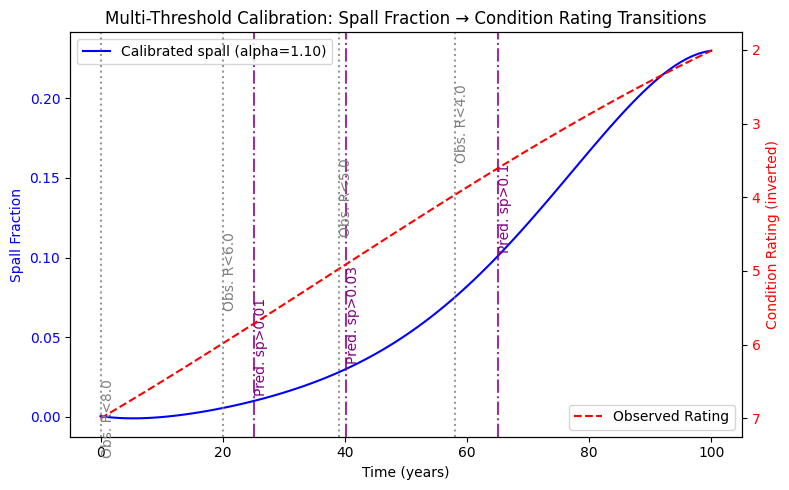

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# -------------------------------
# 1) OBSERVED DATA
# -------------------------------
time_years = np.array([
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
    10,11,12,13,14,15,16,17,18,19,
    20,21,22,23,24,25,26,27,28,29,
    30,31,32,33,34,35,36,37,38,39,
    40,41,42,43,44,45,46,47,48,49,
    50,51,52,53,54,55,56,57,58,59,
    60,61,62,63,64,65,66,67,68,69,
    70,71,72,73,74,75,76,77,78,79,
    80,81,82,83,84,85,86,87,88,89,
    90,91,92,93,94,95,96,97,98,99,
    100
], dtype=float)

condition_rating = np.array([
    # (Same as your code)
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616,6.6031536,6.552538, 6.501722,6.4507128,6.3995176,6.3481436,
    6.296598,6.244888,6.1930208,6.1410036,6.0888436,6.036548,5.984124,
    5.9315788,5.8789196,5.8261536,5.773288,5.72033,5.6672868,5.6141656,
    5.5609736,5.507718,5.454406,5.4010448,5.3476416,5.2942036,5.240738,
    5.187252,5.1337528,5.0802476,5.0267436,4.973248,4.919768,4.8663108,
    4.8128836,4.7594936,4.706148,4.652854,4.5996188,4.5464496,4.4933536,
    4.440338,4.38741,4.3345768,4.2818456,4.2292236,4.176718,4.124336,
    4.0720848,4.0199716,3.9680036,3.916188,3.864532,3.8130428,3.7617276,
    3.7105936,3.659648,3.608898,3.5583508,3.5080136,3.4578936,3.407998,
    3.358334,3.3089088,3.2597296,3.2108036,3.162138,3.11374,3.0656168,
    3.0177756,2.9702236,2.922968,2.876016,2.8293748,2.7830516,2.7370536,
    2.691388,2.646062,2.6010828,2.5564576,2.5121936,2.468298,2.424778,
    2.3816408,2.3388936,2.2965436,2.254598,2.213064,2.1719488,2.1312596,
    2.0910036,2.051188,2.01182
], dtype=float)

time_spall = time_years.copy()  # same time array
spall_fraction = np.array([
    # (Ensure no leading-zero issues!)
    0,0,0,0,0,0,0,0,0,0,
    0,0,0,0,0,0,4.54545e-06,1.36364e-05,3.18182e-05,0.000254545,
    0.000777273,0.001604545,0.002877273,0.004481818,0.00635,0.008213636,
    0.010081818,0.011695455,0.013290909,0.014804545,0.016181818,
    0.017263636,0.018277273,0.019236364,0.020040909,0.02085,0.021609091,
    0.022304545,0.023004545,0.023745455,0.024436364,0.025231818,
    0.026204545,0.027290909,0.028318182,0.029445455,0.030813636,
    0.032231818,0.033722727,0.0355,0.037236364,0.039177273,0.041418182,
    0.043536364,0.045904545,0.048472727,0.051295455,0.054168182,
    0.057095455,0.060222727,0.06345,0.066577273,0.070145455,0.073363636,
    0.076990909,0.080509091,0.084027273,0.087354545,0.090959091,
    0.094459091,0.097827273,0.101386364,0.104936364,0.1087,0.112327273,
    0.115786364,0.119254545,0.122804545,0.126595455,0.130381818,
    0.134081818,0.137836364,0.141677273,0.145481818,0.149195455,
    0.153031818,0.157077273,0.161,0.164945455,0.169122727,0.173195455,
    0.17705,0.180995455,0.185063636,0.189231818,0.19325,0.197472727,
    0.201754545,0.205890909,0.210218182,0.214495455
], dtype=float)

# -------------------------------
# 2) DEFINE RATING vs. SPALL THRESHOLDS
# -------------------------------
# We'll choose a few rating boundaries and matching spall thresholds:
# e.g., rating=8 -> spall=0.01, rating=6-> spall=0.03, rating=5-> spall=0.10, rating=4-> spall=0.25

rating_boundaries = [8.0, 6.0, 5.0, 4.0]
spall_thresholds  = [0.01, 0.03, 0.10, 0.25]

assert len(rating_boundaries) == len(spall_thresholds)

def find_rating_drop_time(t_array, r_array, boundary):
    """
    Return the earliest time 't' at which condition rating falls below 'boundary'.
    If rating never falls below that boundary, return None.
    """
    for t, r in zip(t_array, r_array):
        if r < boundary:
            return t
    return None

def find_spall_cross_time(t_array, s_array, threshold):
    """
    Return the earliest time 't' at which spall fraction >= threshold.
    If spall never crosses that threshold, return None.
    """
    for t, s in zip(t_array, s_array):
        if s >= threshold:
            return t
    return None

# Observed drop times for each rating boundary
observed_times = []
for rb in rating_boundaries:
    t_drop = find_rating_drop_time(time_years, condition_rating, rb)
    observed_times.append(t_drop)

# We'll do a polynomial fit of the spall fraction data for continuous evaluation
from numpy.polynomial import Polynomial
spall_poly = Polynomial.fit(time_spall, spall_fraction, deg=5)  # or deg=4/6

def spall_func(t, alpha):
    """
    Evaluate spall fraction at scaled time alpha*t using the polynomial approximation.
    """
    scaled_t = alpha * t
    return spall_poly(scaled_t)

def spall_cross_time(threshold, alpha):
    """
    Find the earliest time t in [0..120] where spall_func(t, alpha) >= threshold.
    (i.e. spall crosses 'threshold')
    """
    t_candidates = np.linspace(0,120,601)  # check every 0.2 years
    for T in t_candidates:
        if spall_func(T, alpha) >= threshold:
            return T
    return None

def cost_function(params):
    alpha = params[0]
    # For each boundary-threshold pair, find predicted crossing time and compare
    pred_times = []
    for thr in spall_thresholds:
        t_pred = spall_cross_time(thr, alpha)
        pred_times.append(t_pred)
    
    # sum of squared differences
    total_err = 0.0
    for (to, tp) in zip(observed_times, pred_times):
        if to is not None and tp is not None:
            total_err += (to - tp)**2
        else:
            # heavy penalty if we can't find crossing
            total_err += 9999
    return total_err

# -------------------------------
# 3) Optimize
# -------------------------------
from scipy.optimize import minimize

res = minimize(cost_function, x0=[1.0], bounds=[(0.01,10.0)])
alpha_best = res.x[0]
print("Best alpha =", alpha_best)
print("Cost =", res.fun)

alpha_manual = 1.1  # <--- set any value you like
alpha_best = alpha_manual

# -------------------------------
# 4) Visualization
# -------------------------------
# We'll see how well those transitions line up
time_plot = np.linspace(0, 100, 101)
spall_cal = [spall_func(t, alpha_best) for t in time_plot]

# We'll plot the observed rating, spall fraction, and show the transitions
plt.figure(figsize=(8,5))

# Spall fraction (calibrated) on left
ax1 = plt.gca()
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Spall Fraction", color='blue')
ax1.plot(time_plot, spall_cal, 'b-', label=f"Calibrated spall (alpha={alpha_best:.2f})")
ax1.tick_params(axis='y', labelcolor='blue')

# Condition rating on a twin axis
ax2 = ax1.twinx()
ax2.plot(time_years, condition_rating, 'r--', label="Observed Rating")
ax2.set_ylabel("Condition Rating (inverted)", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.invert_yaxis()

# Mark the transitions on the spall curve
for (rb, thr) in zip(rating_boundaries, spall_thresholds):
    # Observed time
    tobs = find_rating_drop_time(time_years, condition_rating, rb)
    # Predicted time
    tpred = spall_cross_time(thr, alpha_best)
    if tobs is not None:
        ax2.axvline(tobs, color='gray', linestyle=':', alpha=0.8)
        ax2.text(tobs, (rb-0.5), f"Obs. R<{rb}", color='gray', rotation=90)
    if tpred is not None:
        ax1.axvline(tpred, color='purple', linestyle='-.', alpha=0.8)
        ax1.text(tpred, thr+0.005, f"Pred. sp>{thr}", color='purple', rotation=90)

ax1.legend(loc='upper left')
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines2, labels2, loc='lower right')

plt.title("Multi-Threshold Calibration: Spall Fraction → Condition Rating Transitions")
plt.tight_layout()
plt.show()


Adjusted Diffusivity_Mean: 0.05
Adjusted ChlorideSurfaceConcentration_Mean: 9.22


100%|████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 200684.40it/s]

Net present cost of total service life repair:
222921.39311850522


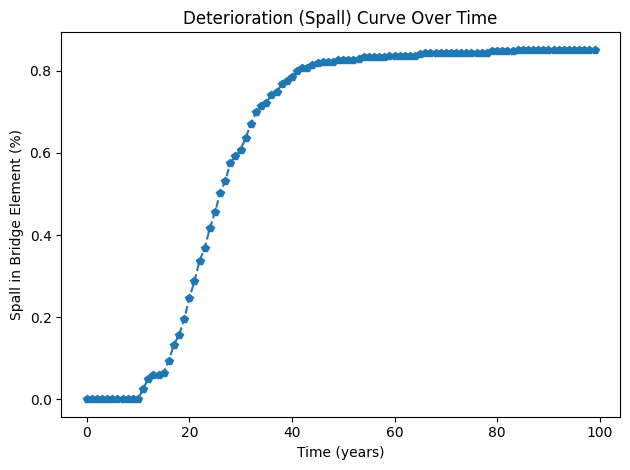

In [8]:
# -*- coding: cp1252 -*-
from scipy.stats import norm
import numpy as np
from scipy import special
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm

# =============================================================
# Geospatial Mapping Table (Example)
# -------------------------------------------------------------
# Condition options:
# 1. Inland, moderate, not in floodplain        -> Diffusivity_Factor = 1.0, ChlorideSurface_Factor = 1.0
# 2. Coastal / Warm, high humidity, not in floodplain -> Diffusivity_Factor = 1.5, ChlorideSurface_Factor = 1.0
# 3. Inland, moderate, in FEMA floodplain           -> Diffusivity_Factor = 1.0, ChlorideSurface_Factor = 1.5
# 4. Coastal / Warm, high humidity, in FEMA floodplain -> Diffusivity_Factor = 1.5, ChlorideSurface_Factor = 1.5
#
# For this example, set:
geo_condition = 1  # choose 1,2,3, or 4 from above.
# =============================================================

# Base parameters (from your mechanistic model code)
Cover_Mean = 2  # cover depth in inches
Cover_Stdev = 0.1  # cover standard deviation in inches
Diffusivity_Mean = 0.05 # inches^2 / year (base value)
Diffusivity_Stdev = 0.015  # inches^2 / year
ChlorideThreshold_Mean = 2.2761  # lbs / yd^3
ChlorideThreshold_Stdev = 0.22761  # lbs / yd^3
ChlorideSurfaceConcentration_Mean = 9.22  # lbs / yd^3 (base value)
ChlorideSurfaceConcentration_Stdev = 3.08  # lbs / yd^3
PropegationTime_Mean = 6 # crack propagation time years
PropegationTime_Stdev = 4  # years
Nitrite_addition = 0 # enter 1 for nitrite, 0 for no nitrite
Nitrite_concentration = 10 # nitrite addition in pcy
native_chloride = 0.1 # native chloride content in concrete, pcy
crack_fraction = 0.06 # fraction of elements containing cracks
crack_diffusivity_ratio = 20 # Diffusivity of crack-containing elements relative to uncracked
crack_diffusivity_stdev = 5
jacket_cost = 10000 # installed Jacket cost
jacket_replacement_time = 25 # jacket durability in years
discount_rate = 0.05 # interest - inflation
spalls_per_jacket = 3 # number of spalls showing before a jacket is required
steps = 220000 # total number of elements in simulation
derating_factor = [0.6, 0.3] # derating factor based on geometry
fraction_derated = [0.4, 0.2] # fraction of elements with geometric derating
elements = 33 # elements per column
time = 100 # simulation time period (years)
sigma_range = 100 # Truncation sigma range
truncl = [1.1, 0.002, 1, 10, 10, 5]  # truncation lower bounds for the 5 input parameters
trunch = [10, 0.1, 20, 60, 60, 20]  # truncation upper bounds

# =============================================================
# Geospatial Adjustments Based on Condition
# =============================================================
# Using our mapping table:
if geo_condition == 1:
    diffusivity_factor = 1.0
    chloride_surface_factor = 1.0
elif geo_condition == 2:
    diffusivity_factor = 1.5
    chloride_surface_factor = 1.0
elif geo_condition == 3:
    diffusivity_factor = 1.0
    chloride_surface_factor = 1.5
elif geo_condition == 4:
    diffusivity_factor = 1.5
    chloride_surface_factor = 1.5
else:
    diffusivity_factor = 1.0
    chloride_surface_factor = 1.0

# Adjust the base parameters:
Diffusivity_Mean *= diffusivity_factor
Diffusivity_Stdev *= diffusivity_factor
ChlorideSurfaceConcentration_Mean *= chloride_surface_factor
ChlorideSurfaceConcentration_Stdev *= chloride_surface_factor

print("Adjusted Diffusivity_Mean:", Diffusivity_Mean)
print("Adjusted ChlorideSurfaceConcentration_Mean:", ChlorideSurfaceConcentration_Mean)

# =============================================================
# (Rest of the mechanistic model code remains similar)
# =============================================================

# This section calculates the number of elements based on user inputs:
element_calculation = 2  # for a bridge deck or flat section
element_size = 100  # square feet
column_perimeter = 10  # square feet
corrosion_zone = 10  # feet of area within corrosion zone
number_of_piles = 2000  # e.g., bridge length divided by 15
flat_footage = 20000  # total square footage of affected zone
repair_size = 100  # square feet

if element_calculation == 1:
    elements = int(column_perimeter * corrosion_zone / element_size)
    steps = elements * number_of_piles
elif element_calculation == 2:
    steps = int(flat_footage / element_size)
    elements = repair_size / element_size

# =============================================================
# Calculate chloride threshold adjustments based on rebar type:
rebar_type = 0  # 0 for manual entry
if rebar_type == 1:
    ChlorideThreshold_Mean = 0.004 * cement_factor
elif rebar_type == 2:
    ChlorideThreshold_Mean = 0.004 * cement_factor * 4
elif rebar_type == 3:
    ChlorideThreshold_Mean = 0.004 * cement_factor * 10
if rebar_type != 0:
    ChlorideSurfaceConcentration_Stdev = ChlorideThreshold_Mean / 2

averagevalues = [Cover_Mean, Diffusivity_Mean, ChlorideThreshold_Mean - native_chloride, ChlorideSurfaceConcentration_Mean, PropegationTime_Mean]
StandardDeviations = [Cover_Stdev, Diffusivity_Stdev, ChlorideThreshold_Stdev, ChlorideSurfaceConcentration_Stdev, PropegationTime_Stdev]

# =============================================================
# Build tables for deratings
derating_total = [0.0]
fraction_derated.append(1 - sum(fraction_derated))
derating_factor.append(1)
for i in range(len(derating_factor)):
    derating_total.append(derating_total[i] + fraction_derated[i])
derating_array = []
for i in tqdm(range(steps)):
    for j in range(len(derating_factor)):
        if i >= derating_total[j] * steps and i < derating_total[j + 1] * steps:
            derating_array.append(derating_factor[j])

# =============================================================
# Crack diffusivity variation
crack_array = []
for i in range(steps):
    t = 0
    while t == 0:
        proxy = random.gauss(0, 1)
        if truncl[5] < crack_diffusivity_ratio + proxy * crack_diffusivity_stdev < trunch[5]:
            crack_array.append(crack_diffusivity_ratio + crack_diffusivity_stdev * proxy)
            t = 1

# =============================================================
# Define function for time to corrosion (spall initiation)
if Nitrite_addition == 0:
    def funct(a, b, c, d, e, f):
        if c / d < 1:
            return np.square(a) / (4 * b * np.square(special.erfinv(1 - c / d))) + e
        return 1000
else:
    def funct(a, b, c, d, e, f):
        return np.square(a) / (4 * b * np.square(special.erfinv(1 - (f * (d - c) / (f + d) + c) / d))) + e

# =============================================================
# Populate Monte Carlo matrices
monte_in = []
monte_out = []
monte_bincount = []

for i in range(steps):
    monte_out.append(int(0))
for i in range(5):
    t = []
    for j in range(steps):
        t.append(0.0)
    monte_in.append(t)

for i in range(5):
    for j in range(steps):
        t = 0
        while t == 0:
            monte_in[i][j] = random.gauss(0, 1)
            a = 1
            if i == 1:
                a /= derating_array[j]
            if random.random() < crack_fraction and i == 1:
                a = crack_array[i]
            if trunch[i] > monte_in[i][j] * StandardDeviations[i] + averagevalues[i] > truncl[i]:
                monte_in[i][j] = monte_in[i][j] * StandardDeviations[i] + (a * averagevalues[i])
                t = 1

for i in range(steps):
    monte_out[i] = funct(monte_in[0][i], monte_in[1][i], monte_in[2][i], monte_in[3][i], monte_in[4][i], Nitrite_concentration)
    monte_out[i] = math.floor(monte_out[i])
for i in range(int(time)):
    monte_bincount.append(0.0)
for i in range(len(monte_out)):
    if int(len(monte_bincount) > monte_out[i] > 0):
        a = int(monte_out[i])
        monte_bincount[a] += 1

cost = []
jackets = []
jacket_sum = [0.0]
jacket_current = [0.0]
cost_sum = [0.0]

for i in range(0, len(monte_bincount)):
    if i > 0:
        monte_bincount[i] = monte_bincount[i] * ((steps - elements * jacket_current[i - 1]) / steps)
    if i <= jacket_replacement_time - 1:
        jackets.append(monte_bincount[i] / spalls_per_jacket)
    else:
        jackets.append(monte_bincount[i] / spalls_per_jacket + jackets[i - jacket_replacement_time])
    if i > 0:
        jacket_sum.append(jackets[i] + jacket_sum[i - 1])
        jacket_current.append(monte_bincount[i] / spalls_per_jacket + jacket_current[i - 1])
    cost.append(jackets[i] * jacket_cost * ((1 - discount_rate) ** i))
    if i > 0:
        cost_sum.append(cost_sum[i - 1] + cost[i])

print("Net present cost of total service life repair:")
print(cost_sum[time - 1])

x = [0]
monte_bincount[0] = monte_bincount[0] / steps
for i in range(1, len(monte_bincount)):
    monte_bincount[i] = monte_bincount[i] / steps + monte_bincount[i - 1]
    x.append(i)

plt.plot(x, monte_bincount, 'p--')
plt.xlabel('Time (years)')
plt.ylabel('Spall in Bridge Element (%)')
plt.title("Deterioration (Spall) Curve Over Time")
plt.tight_layout()
plt.show()


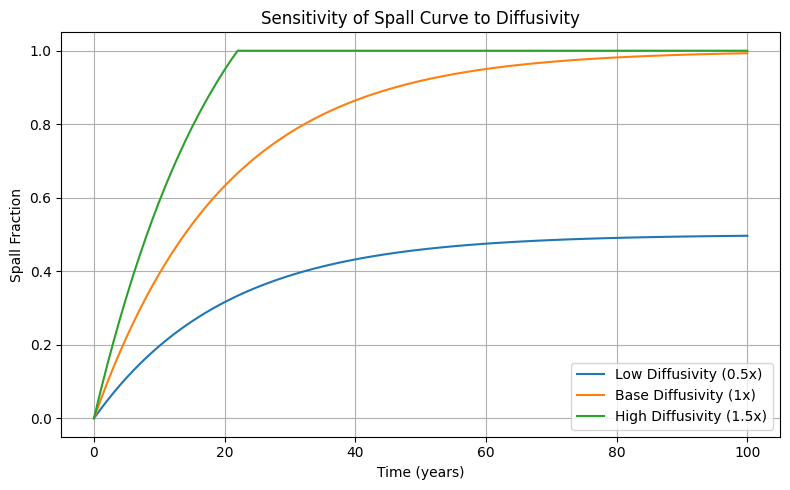

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm
from scipy import special

# Base parameters (from your mechanistic model code)
Cover_Mean = 2  # cover depth in inches
Cover_Stdev = 0.1  
Diffusivity_base = 0.05  # base diffusion coefficient (in^2/year)
Diffusivity_Stdev_base = 0.015  
ChlorideThreshold_Mean = 2.2761  
ChlorideThreshold_Stdev = 0.22761  
ChlorideSurfaceConcentration_Mean = 9.22  
ChlorideSurfaceConcentration_Stdev = 3.08  
PropegationTime_Mean = 6  
PropegationTime_Stdev = 4  
Nitrite_addition = 0  
Nitrite_concentration = 10  
native_chloride = 0.1  
crack_fraction = 0.06  
crack_diffusivity_ratio = 20  
crack_diffusivity_stdev = 5  
# Other parameters omitted for brevity...

# Define a function that runs your model and returns the spall curve.
# For simplicity, let's assume your model ultimately produces a spall fraction curve over time.
# Here, we'll simulate a dummy spall curve that depends on the diffusion coefficient.

def simulate_spall_curve(diffusivity):
    # We'll assume that a higher diffusivity leads to faster spall growth.
    # This is a simplified example: spall fraction = (diffusivity / diffusivity_base) * f(t)
    # where f(t) is some base function, say f(t) = 1 - exp(-0.05*t)
    t = np.linspace(0, 100, 101)
    f_t = 1 - np.exp(-0.05 * t)
    spall = (diffusivity / Diffusivity_base) * f_t  # scaling spall by diffusivity ratio
    # Limit spall fraction to a maximum of 1 (or 100%)
    spall = np.clip(spall, 0, 1)
    return t, spall

# Define diffusion coefficients to test (50% below, base, 50% above)
diffusivity_values = [Diffusivity_base * 0.5, Diffusivity_base, Diffusivity_base * 1.5]
labels = ["Low Diffusivity (0.5x)", "Base Diffusivity (1x)", "High Diffusivity (1.5x)"]

plt.figure(figsize=(8,5))
for d_val, lab in zip(diffusivity_values, labels):
    t, spall = simulate_spall_curve(d_val)
    plt.plot(t, spall, label=lab)

plt.xlabel("Time (years)")
plt.ylabel("Spall Fraction")
plt.title("Sensitivity of Spall Curve to Diffusivity")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Environmental Inputs:
  Average Temperature (K): 298
  Relative Humidity (%): 80
  Annual Precipitation (mm): 1800
  Distance to Coast (km): 5
  FEMA Flood Zone: A

Multipliers:
  Temperature Multiplier: 1.3963811028353466
  Humidity Multiplier: 1.0
  Precipitation Multiplier: 0.88
  Wind/Wave Multiplier: 0.0101069204986282
  Flood Zone Multiplier: 1.2

Adjusted Model Parameters:
  Adjusted Diffusivity (D): 0.06981905514176732 in^2/year
  Adjusted Surface Chloride (Cs): 0.12707155499638909 lbs/yd^3


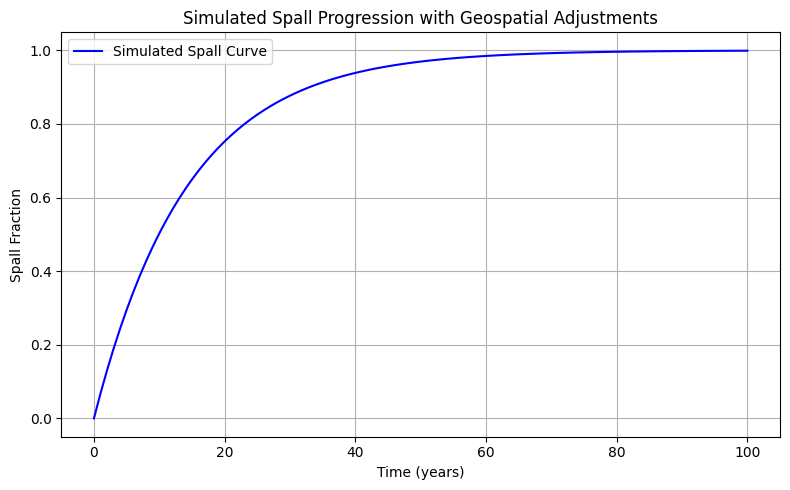

In [5]:
import numpy as np
import math

# --- Constants for Temperature Adjustment (Arrhenius) ---
R = 8.314  # J/(mol·K)
E_a = 50000  # J/mol, example activation energy
T_ref = 293.15  # Reference temperature in Kelvin (20°C)

def temperature_multiplier(T_avg):
    """Calculate multiplier for D based on average temperature T_avg (in Kelvin)."""
    return math.exp((E_a / R) * (1.0 / T_ref - 1.0 / T_avg))

def humidity_multiplier(RH):
    """Return multiplier for D based on relative humidity (RH, in %)."""
    if RH >= 80:
        return 1.0
    else:
        return RH / 80.0

def precipitation_multiplier(P):
    """Return a factor for surface chloride wash-off based on annual precipitation P (mm/year).  
       Higher rainfall leads to lower effective chloride concentration."""
    if P < 1500:
        return 1.0
    elif P > 2500:
        return 0.6
    else:
        return 1.0 - 0.4 * ((P - 1500) / 1000.0)

def wind_wave_multiplier(distance):
    """Return multiplier for surface chloride based on distance (km) from the coast.  
       Closer to the coast (small distance) gets higher salt deposition."""
    return 1.5 * math.exp(-distance)

def flood_zone_multiplier(flood_zone):
    """Return multiplier for surface chloride based on FEMA flood zone."""
    zone = flood_zone.upper()
    if zone in ["VE", "V"]:
        return 1.5
    elif zone in ["AE", "A"]:
        return 1.2
    else:
        return 1.0

# --- Base Model Parameters (from your mechanistic model) ---
D_base = 0.05  # Diffusion coefficient in in^2/year (base value)
Cs_base = 9.22  # Chloride surface concentration in lbs/yd^3 (base value)

# --- Example Environmental Inputs for a Florida Bridge ---
# (These values would be derived from NOAA and FEMA datasets in a real application.)
T_avg = 298        # Average temperature (K); e.g., 25°C for coastal FL.
RH_avg = 80         # Average relative humidity (%).
P_annual = 1800       # Annual precipitation (mm/year).
distance_to_coast = 5  # Distance from the coast in km.
flood_zone = "A"     # FEMA flood zone (e.g., "VE" for high hazard coastal zones).

# --- Compute Multipliers ---
temp_mult = temperature_multiplier(T_avg)
rh_mult = humidity_multiplier(RH_avg)
precip_mult = precipitation_multiplier(P_annual)
wind_wave_mult = wind_wave_multiplier(distance_to_coast)
flood_mult = flood_zone_multiplier(flood_zone)

# --- Adjusted Model Parameters ---
# For diffusion coefficient D, the effective multiplier is from temperature and humidity.
D_adjusted = D_base * temp_mult * rh_mult
# For surface chloride concentration Cs, multiply base value by wind/wave and flood factors,
# and reduce it by the wash-off effect (precipitation multiplier).
Cs_adjusted = Cs_base * wind_wave_mult * flood_mult / precip_mult

print("Environmental Inputs:")
print("  Average Temperature (K):", T_avg)
print("  Relative Humidity (%):", RH_avg)
print("  Annual Precipitation (mm):", P_annual)
print("  Distance to Coast (km):", distance_to_coast)
print("  FEMA Flood Zone:", flood_zone)
print("")
print("Multipliers:")
print("  Temperature Multiplier:", temp_mult)
print("  Humidity Multiplier:", rh_mult)
print("  Precipitation Multiplier:", precip_mult)
print("  Wind/Wave Multiplier:", wind_wave_mult)
print("  Flood Zone Multiplier:", flood_mult)
print("")
print("Adjusted Model Parameters:")
print("  Adjusted Diffusivity (D):", D_adjusted, "in^2/year")
print("  Adjusted Surface Chloride (Cs):", Cs_adjusted, "lbs/yd^3")

# --- Integration into the Corrosion Model ---
# Now, plug D_adjusted and Cs_adjusted into your chloride corrosion model.
# For example, in your model code, instead of using Diffusivity_Mean and ChlorideSurfaceConcentration_Mean,
# you would use D_adjusted and Cs_adjusted.

# (The remainder of your corrosion model code would proceed as before,
# using these adjusted values to simulate chloride ingress, crack initiation, spall development, etc.)

# For demonstration, here's a simplified "dummy" simulation for spall progression:
def simulate_spall_curve(D, t_end=100, num_points=101):
    """Simulate a spall fraction curve over time as a function of diffusivity D.
       For simplicity, we assume spall fraction f(t) = 1 - exp(-k * t) with k proportional to D."""
    t = np.linspace(0, t_end, num_points)
    # Let k be proportional to D; using k = 0.05 * (D / D_base)
    k = 0.05 * (D / D_base)
    spall = 1 - np.exp(-k * t)
    spall = np.clip(spall, 0, 1)
    return t, spall

# Simulate spall curve using the adjusted diffusivity.
t_sim, spall_sim = simulate_spall_curve(D_adjusted)

plt.figure(figsize=(8,5))
plt.plot(t_sim, spall_sim, 'b-', label="Simulated Spall Curve")
plt.xlabel("Time (years)")
plt.ylabel("Spall Fraction")
plt.title("Simulated Spall Progression with Geospatial Adjustments")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


-------------------------------------------------------
 Environmental Inputs:
  Average Temperature (K): 298.15
  Relative Humidity (%): 80.0
  Annual Precipitation (mm): 1000
  Distance to Coast (km): 0.50
  FEMA Flood Zone: X
-------------------------------------------------------
 Derived Multipliers:
  Temperature Multiplier: 1.411
  Humidity Multiplier: 1.000
  Precipitation Multiplier: 1.000
  Wind/Wave Multiplier: 0.910
  Flood Zone Multiplier: 1.000
-------------------------------------------------------
 Adjusted Model Parameters:
  Adjusted Diffusivity (D): 0.0705 in^2/year
  Adjusted Surface Chloride (Cs): 8.39 lbs/yd^3
-------------------------------------------------------



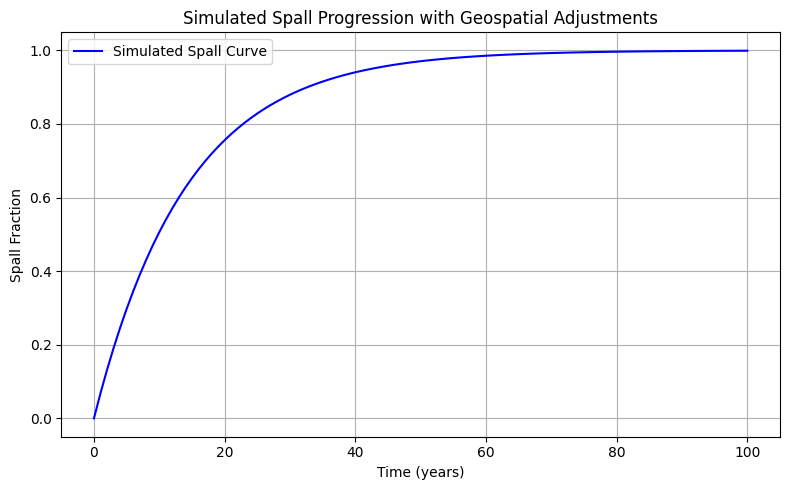

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt

# --- Constants for Temperature Adjustment (Arrhenius Equation) ---
R = 8.314         # J/(mol·K)
E_a = 50000       # J/mol (example activation energy)
T_ref = 293.15    # Reference temperature in Kelvin (20°C)

def temperature_multiplier(T_avg):
    """Calculate multiplier for D based on average temperature T_avg (in Kelvin)."""
    return math.exp((E_a / R) * (1.0 / T_ref - 1.0 / T_avg))

def humidity_multiplier(RH):
    """Return multiplier for D based on relative humidity (RH, in %)."""
    if RH >= 80:
        return 1.0
    else:
        return RH / 80.0

def precipitation_multiplier(P):
    """Return a factor for surface chloride wash-off based on annual precipitation P (mm/year).
       Higher rainfall leads to lower effective chloride concentration."""
    if P < 1500:
        return 1.0
    elif P > 2500:
        return 0.6
    else:
        return 1.0 - 0.4 * ((P - 1500) / 1000.0)

def wind_wave_multiplier(distance):
    """Return multiplier for surface chloride based on distance (km) from the coast.
       Closer to the coast (small distance) gets higher salt deposition."""
    return 1.5 * math.exp(-distance)

def flood_zone_multiplier(flood_zone):
    """Return multiplier for surface chloride based on FEMA flood zone.
       Zones 'VE' and 'V' are assigned a higher multiplier than AE/A or non-flood zones."""
    zone = flood_zone.upper()
    if zone in ["VE", "V"]:
        return 1.5
    elif zone in ["AE", "A"]:
        return 1.2
    else:
        return 1.0

# --- Base Model Parameters (from your mechanistic corrosion model) ---
D_base = 0.05    # Diffusion coefficient in in^2/year (base value)
Cs_base = 9.22   # Chloride surface concentration in lbs/yd^3 (base value)

# --- Example Environmental Inputs for a Florida Bridge ---
# (These values would be derived from NOAA and FEMA datasets in a real application.)
T_avg = 298.15            # Average temperature (K); e.g., 25°C for coastal FL.
RH_avg = 80               # Average relative humidity (%).
P_annual = 1000           # Annual precipitation (mm/year).
distance_to_coast = 0.5     # Distance from the coast in km.
flood_zone = "X"          # FEMA flood zone (e.g., "VE" for high hazard coastal zones).

# --- Compute Multipliers ---
temp_mult = temperature_multiplier(T_avg)
rh_mult = humidity_multiplier(RH_avg)
precip_mult = precipitation_multiplier(P_annual)
wind_wave_mult = wind_wave_multiplier(distance_to_coast)
flood_mult = flood_zone_multiplier(flood_zone)

# --- Adjusted Model Parameters ---
# Adjusted diffusion coefficient: affected by temperature and humidity.
D_adjusted = D_base * temp_mult * rh_mult
# Adjusted surface chloride: modified by wind/wave and flood zone, then reduced by wash-off effect.
Cs_adjusted = Cs_base * wind_wave_mult * flood_mult / precip_mult

# --- Print a Nicely Formatted Summary ---
print("-------------------------------------------------------")
print(" Environmental Inputs:")
print("  Average Temperature (K): {:.2f}".format(T_avg))
print("  Relative Humidity (%): {:.1f}".format(RH_avg))
print("  Annual Precipitation (mm): {:.0f}".format(P_annual))
print("  Distance to Coast (km): {:.2f}".format(distance_to_coast))
print("  FEMA Flood Zone: {}".format(flood_zone))
print("-------------------------------------------------------")
print(" Derived Multipliers:")
print("  Temperature Multiplier: {:.3f}".format(temp_mult))
print("  Humidity Multiplier: {:.3f}".format(rh_mult))
print("  Precipitation Multiplier: {:.3f}".format(precip_mult))
print("  Wind/Wave Multiplier: {:.3f}".format(wind_wave_mult))
print("  Flood Zone Multiplier: {:.3f}".format(flood_mult))
print("-------------------------------------------------------")
print(" Adjusted Model Parameters:")
print("  Adjusted Diffusivity (D): {:.4f} in^2/year".format(D_adjusted))
print("  Adjusted Surface Chloride (Cs): {:.2f} lbs/yd^3".format(Cs_adjusted))
print("-------------------------------------------------------\n")

# --- Integration into the Corrosion Model ---
# Now, these adjusted parameters (D_adjusted and Cs_adjusted) are used in place of the base values in the chloride corrosion model.
# For demonstration, we include a simplified simulation of spall progression.

def simulate_spall_curve(D, t_end=100, num_points=101):
    """Simulate a spall fraction curve over time as a function of diffusivity D.
       For simplicity, assume spall fraction f(t) = 1 - exp(-k * t) with k proportional to D."""
    t = np.linspace(0, t_end, num_points)
    # k is proportional to D; here we use k = 0.05 * (D / D_base)
    k = 0.05 * (D / D_base)
    spall = 1 - np.exp(-k * t)
    spall = np.clip(spall, 0, 1)
    return t, spall

# Simulate spall curve using the adjusted diffusivity.
t_sim, spall_sim = simulate_spall_curve(D_adjusted)

plt.figure(figsize=(8,5))
plt.plot(t_sim, spall_sim, 'b-', label="Simulated Spall Curve")
plt.xlabel("Time (years)")
plt.ylabel("Spall Fraction")
plt.title("Simulated Spall Progression with Geospatial Adjustments")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


100%|█████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 40062.12it/s]

net present cost of total service life repair:
258794.53514628994


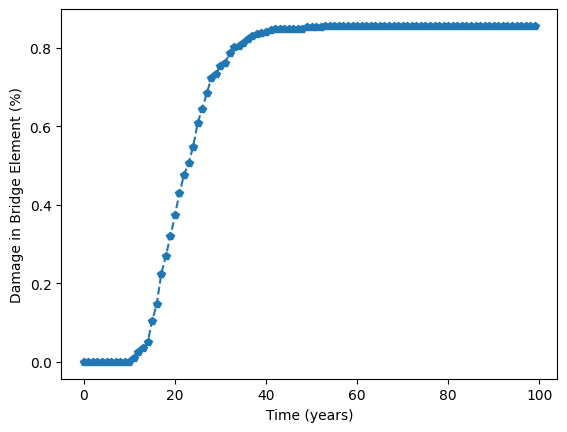

In [21]:
# -*- coding: cp1252 -*-
from scipy.stats import norm
import numpy as np
from scipy import special
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm

Cover_Mean = 2  # cover depth in inches
Cover_Stdev = .1  # cover standard deviation in inches
Diffusivity_Mean = 0.0705 # inches^2 / year
Diffusivity_Stdev = 0.015  # inches^2 / year
ChlorideThreshold_Mean = 2.2761  # lbs / yd^3
ChlorideThreshold_Stdev = 0.22761  # lbs / yd^3
ChlorideSurfaceConcentration_Mean = 8.39 # lbs / yd^3
ChlorideSurfaceConcentration_Stdev = 3.08  # lbs / yd^3
PropegationTime_Mean = 6 # crack propegation time years
PropegationTime_Stdev = 4  # years
Nitrite_addition = 0 #enter 1 for nitrite, 0 for no nitrite
Nitrite_concentration = 10 #nitrite addition in pcy
native_chloride = 0.1 #native chloride content in concrete, pcy
crack_fraction = .06 #fraction of elements containing cracks
crack_diffusivity_ratio = 20 #Diffusivity of crack containing elements relative to uncracked
crack_diffusivity_stdev = 5
jacket_cost = 10000 #installed Jacket cost
jacket_replacement_time = 25 #jacket durability in years
discount_rate = .05 #interest - inflation
spalls_per_jacket = 3 #number of spalls showing before a jacket is required
steps = 220000 #total number of elements in simulation
derating_factor = [0.6,0.3] #derating factor i based on geometry, if you don't know what this is make it 1, allows for multiple deratings
fraction_derated = [0.4,0.2] #fraction of elements with geometric derating i, allows for multiple, index is the same as derating factor's
elements = 33 #elements per column
time = 100 #time period ofver which the simulation is run
sigma_range = 100#Truncation sigma range
truncl = [1.1,.002,1,10,10,5]#truncation lower bounds for the 5 input parameters, the last number is for the crack diffusivity ratio
trunch = [10,.1,20,60,60,20] #truncation upper bounds
# This section calculates Diffusivity based on common user inputs
diffusion_type = 0 #0 for entered, 1 for rapid permeability, 2 for prediction based on concrete type
rapid_permeability = 300 #output of the rapid permeability test in coulombs
water_ratio = .5 #water to cement ratio
cement_factor = 600 # lbs of cement in one cubic yard of concrete
pozzolan_addition = 1 # are pozzolans present? enter 1 if yes, 0 if no
if diffusion_type == 1:
    Diffusivity_Mean = .0005 * rapid_permeability1**.78
    Diffusivity_Stdev = Diffusivity_Mean1/2
elif diffusion_type == 2:
    if pozzolan_addition == 1: F1 = 1
    else: F = 3
    Diffusivity_Mean = .01*(1+(water_ratio-.32)/.09)*(1+(752-cement_factor)/94)*F1
    Diffusivity_Stdev = Diffusivity_Mean/2
# end of section

#this section calculates the number of elements from common user iputs
element_calculation = 2 #how the program calculates the size of the simulation, 0 for manual entry, 1 for bridge piles
#for a bridge deck or other flat section like a hotel front enter 2
element_size = 100 #size of each discretized element in square feet, if no data assume 3
column_perimeter = 10 #perimeter of each column in square feet, often ~10
corrosion_zone = 10 #feet of area within corrosion zone
number_of_piles = 2000 # often something like bridge length in feet divided by 15
flat_footage = 20000 #total square footage of affected zone
repair_size = 100 #size of section repaired, assume same as element size if repairs are simple patching
if element_calculation ==1:
    elements = int(column_perimeter *corrosion_zone/element_size)
    steps = elements * number_of_piles
elif element_calculation ==2:
    steps = int(flat_footage/element_size)
    elements = repair_size / element_size
#end of section
#this section calculates the chloride threshold from common user inputs
rebar_type = 0 #0 for manual entry, 1 for plain steel, 2 for CRR, 3 for stainless
if rebar_type == 1:
    ChlorideThreshold_Mean = .004 * cement_factor
elif rebar_type == 2:
    ChlorideThreshold_Mean = .004 * cement_factor * 4
elif rebar_type == 3:
    ChlorideThreshold_Mean = .004 * cement_factor * 10
if rebar_type != 0:
    ChlorideSurfaceConcentration_Stdev = ChlorideThreshold_Mean/2
#end section
averagevalues = [Cover_Mean, Diffusivity_Mean, ChlorideThreshold_Mean-native_chloride, ChlorideSurfaceConcentration_Mean,
                 PropegationTime_Mean]
StandardDeviations = [Cover_Stdev, Diffusivity_Stdev, ChlorideThreshold_Stdev, ChlorideSurfaceConcentration_Stdev,
                      PropegationTime_Stdev]
# Assembles the above properties into tables of means and standard deviations

#Builds a table of deratings
derating_total = [0.0]
fraction_derated.append(1-sum(fraction_derated))
derating_factor.append(1)

for i in range(len(derating_factor)):
    derating_total.append(derating_total[i] + fraction_derated[i])
derating_array = []
for i in tqdm(range(steps)):
    for j in range(len(derating_factor)):
        if (i >=derating_total[j] * steps and i < derating_total[j+1] * steps):
            derating_array.append(derating_factor[j])
#End of section

#crack diffusivity variation
crack_array = []
for i in range (steps):
    t = 0
    while t == 0:
        proxy  = random.gauss(0,1)
        if truncl[5] < crack_diffusivity_ratio + proxy * crack_diffusivity_stdev < trunch[5]:
            crack_array.append(crack_diffusivity_ratio + crack_diffusivity_stdev * proxy)
            t = 1
#end of section


# print (crack_array[1])

if Nitrite_addition == 0:  #funct calculates the time to propegation for a given set of inputs
    def funct(a,b,c,d,e,f):
        if c/d < 1: 
            return np.square(a) / (4 * b * np.square(special.erfinv(1 - c / d))) + e #standard calculation of crack initiation time
        return 1000
else:
    def funct(a,b,c,d,e,f):
        return np.square(a) / (4 * b * np.square(special.erfinv(1 - (f * (d-c)/(f+d)+c)/d))) + e #crack initiation using Ct depentend on Nitrite addition and Cs

    #here we are just filling in the matrices that we will use for the monte carlos simulation
monte_in = []
monte_out = []
monte_bincount = []

for i in range(steps):
    monte_out.append(int(0))

for i in range(5):
    t = []
    for j in range(steps):
        t.append(0.0)
    monte_in.append(t)

#the next sextion creates normally distributed variables with mean 0 and std 1 and multiplies them with the standard deviations and
#adds the mean, this gives a random value probibalistically distributed around the input mean
#there are two diffusivity corrections, basically the mean is multiplied by the crack diffusivity ratio or derating factor
#with some random probability equal to the input probability that a given element will have that characteristic
#monte_in is now populated with variables for each of the 5 input parameters, i references the input parameter and
#j references the element
for i in range(5):
    for j in range(steps):
        t = 0
        while t==0:
            monte_in[i][j] = random.gauss(0,1)
            a = 1
            if i ==1:
                a /= derating_array[j]
            if random.random() < crack_fraction and i == 1: #accounting for cracks
                a = crack_array[i]
            if  trunch[i] > monte_in[i][j] * StandardDeviations[i] + averagevalues[i] > truncl[i]:
                monte_in[i][j] = monte_in[i][j] * StandardDeviations[i] + (a * averagevalues[i])
                t=1
#the next section calculates a time to corrosion in years for each element in the monte_in array
#Monte_out is now populated with a time to corrosion for each element i, math.floor converts each element in
#monte_out to the integer below, since the outputs of funct are floats and we are going to be calculating corrosion times
#with a granularity of one year
for i in range(steps):
    monte_out[i]=funct(monte_in[0][i],monte_in[1][i],monte_in[2][i],monte_in[3][i],monte_in[4][i],Nitrite_concentration)
    monte_out[i] = math.floor(monte_out[i])
for i in range(int(time)):
    monte_bincount.append(0.0)
#the next section populates an array monte_mincount with the number failures that happened at any given year
#monte_bincount is basically a histogram of the times to corrosion, where each element i in the array references
#year i in the simulation
for i in range(len(monte_out)):
    if int(len(monte_bincount) > monte_out[i] > 0):
        a = int(monte_out[i])
        monte_bincount[a] += 1
cost = []
jackets = []
jacket_sum = [0.0]
jacket_current = [0.0]
cost_sum = [0.0]
#the next section calculates the number of elements damaged based on the number of jackets and the cathdic protection effect
#the number of jackets needed at any given year
#the number of jackets that have been put on total
#the number of jackets that are currently on
#the net present cost of repair for any given year
#the total net present cost of repair up until any given year
#each time a repair is given to a column the rest of the column is taken out of the simulation statistically
# such that the damaged fraction of the concrete converges to (damaged area per repair / size of each column)
for i in range(0,len(monte_bincount)):
    if i > 0:
        monte_bincount[i] = monte_bincount[i]*((steps - elements*jacket_current[i-1])/steps)
    if i <= jacket_replacement_time - 1:
        jackets.append(monte_bincount[i]/spalls_per_jacket)
    else:
        jackets.append(monte_bincount[i]/spalls_per_jacket + jackets[i-jacket_replacement_time])
    if i > 0: 
        jacket_sum.append(jackets[i] + jacket_sum[i-1])
        jacket_current.append(monte_bincount[i]/spalls_per_jacket + jacket_current[i-1])
    cost.append(jackets[i]*jacket_cost*((1-discount_rate)**i))
    if i>0:
        cost_sum.append(cost_sum[i-1]+cost[i])

#this just prints the numerical value of the present cost of maintenance at the service life of the structure
print ("net present cost of total service life repair:")
print (cost_sum[time-1])
x = [0]
monte_bincount[0]=monte_bincount[0]/steps
for i in range(1,len(monte_bincount)):
    monte_bincount[i] = monte_bincount[i]/steps+monte_bincount [i-1]
    x.append(i)
#here we print out our four plots
# plt.subplot(2,2,1)
plt.plot(x,monte_bincount,'p--')
plt.xlabel('Time (years)')
plt.ylabel('Damage in Bridge Element (%)')


plt.show()#outputs a graph of the damage function versus time

In [ ]:
#SENSITIVITY ANALYSIS

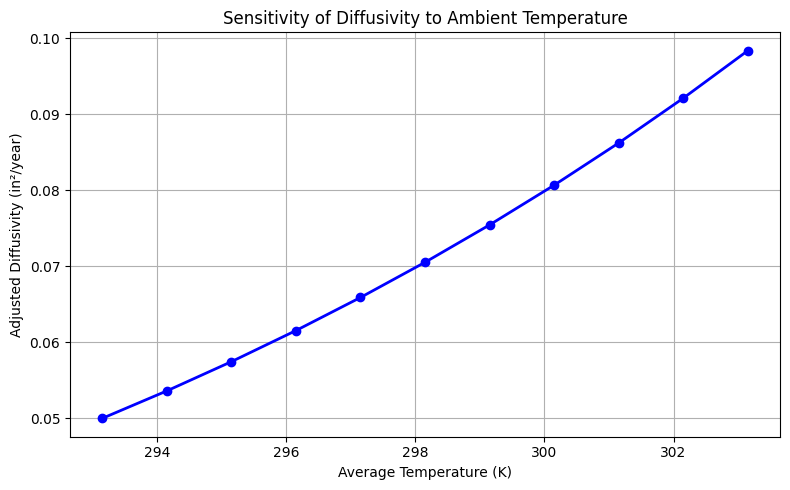

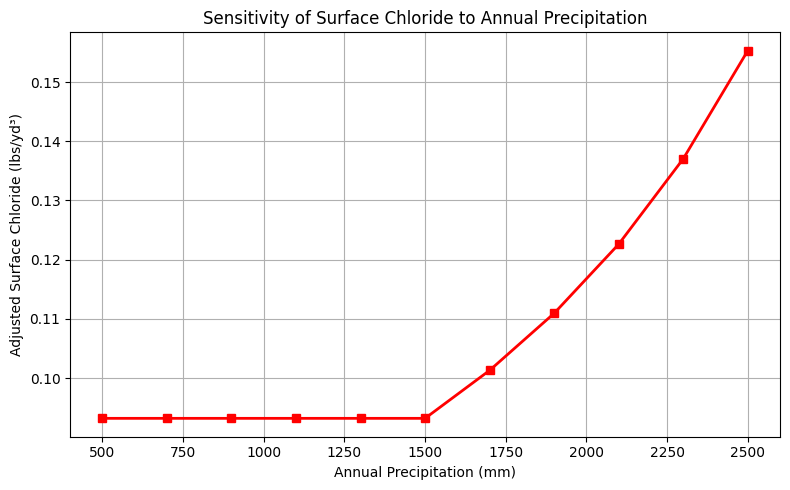

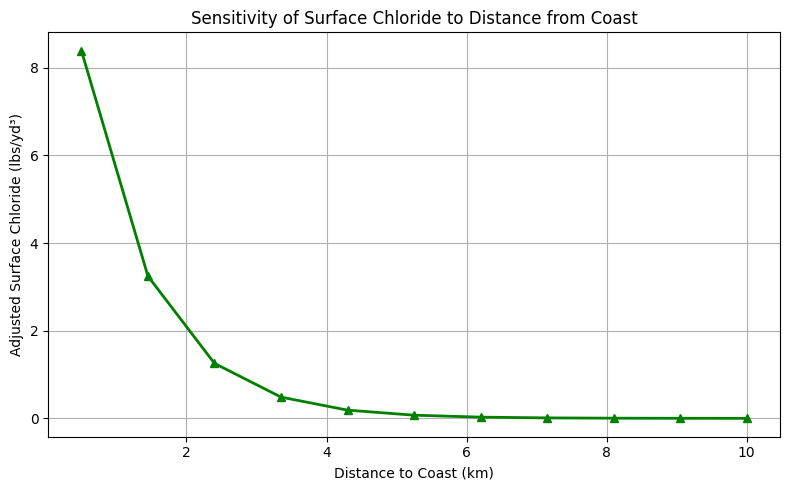

In [19]:
import numpy as np
import math
import matplotlib.pyplot as plt

# --- Constants for Temperature Adjustment (Arrhenius Equation) ---
R = 8.314         # J/(mol·K)
E_a = 50000       # J/mol, example activation energy
T_ref = 293.15    # Reference temperature in Kelvin (20°C)

def temperature_multiplier(T_avg):
    """Calculate multiplier for D based on average temperature T_avg (in Kelvin)."""
    return math.exp((E_a / R) * (1.0 / T_ref - 1.0 / T_avg))

def humidity_multiplier(RH):
    """Return multiplier for D based on relative humidity (RH, in %)."""
    if RH >= 80:
        return 1.0
    else:
        return RH / 80.0

def precipitation_multiplier(P):
    """Return a factor for surface chloride wash-off based on annual precipitation P (mm/year).
       Higher rainfall leads to lower effective chloride concentration."""
    if P < 1500:
        return 1.0
    elif P > 2500:
        return 0.6
    else:
        return 1.0 - 0.4 * ((P - 1500) / 1000.0)

def wind_wave_multiplier(distance):
    """Return multiplier for surface chloride based on distance (km) from the coast.
       Closer to the coast gets higher salt deposition."""
    return 1.5 * math.exp(-distance)

def flood_zone_multiplier(flood_zone):
    """Return multiplier for surface chloride based on FEMA flood zone."""
    zone = flood_zone.upper()
    if zone in ["VE", "V"]:
        return 1.5
    elif zone in ["AE", "A"]:
        return 1.2
    else:
        return 1.0

# --- Base Model Parameters ---
D_base = 0.05    # Diffusion coefficient in in^2/year (base value)
Cs_base = 9.22   # Chloride surface concentration in lbs/yd^3 (base value)

# --- Default Environmental Inputs (Example for a Florida Bridge) ---
# These can be modified in sensitivity analyses.
RH_avg_default = 80         # Relative Humidity (%)
distance_to_coast_default = 5  # Distance (km)
flood_zone_default = "X"    # FEMA flood zone

# --- Sensitivity Analysis for Ambient Temperature ---
# We vary T_avg from 293K (20°C) to 303K (30°C)
T_avg_values = np.linspace(293.15, 303.15, 11)
D_adjusted_list = []
for T in T_avg_values:
    temp_mult = temperature_multiplier(T)
    rh_mult = humidity_multiplier(RH_avg_default)  # using default RH
    D_adj = D_base * temp_mult * rh_mult
    D_adjusted_list.append(D_adj)

# Plot Adjusted Diffusivity vs Ambient Temperature
plt.figure(figsize=(8,5))
plt.plot(T_avg_values, D_adjusted_list, 'bo-', linewidth=2)
plt.xlabel("Average Temperature (K)")
plt.ylabel("Adjusted Diffusivity (in²/year)")
plt.title("Sensitivity of Diffusivity to Ambient Temperature")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Sensitivity Analysis for Annual Precipitation ---
# We vary P_annual from 500 mm/year to 2500 mm/year
P_annual_values = np.linspace(500, 2500, 11)
Cs_adjusted_list = []
for P in P_annual_values:
    precip_mult = precipitation_multiplier(P)
    wind_wave_mult_val = wind_wave_multiplier(distance_to_coast_default)
    flood_mult_val = flood_zone_multiplier(flood_zone_default)
    Cs_adj = Cs_base * wind_wave_mult_val * flood_mult_val / precip_mult
    Cs_adjusted_list.append(Cs_adj)

# Plot Adjusted Surface Chloride vs Annual Precipitation
plt.figure(figsize=(8,5))
plt.plot(P_annual_values, Cs_adjusted_list, 'rs-', linewidth=2)
plt.xlabel("Annual Precipitation (mm)")
plt.ylabel("Adjusted Surface Chloride (lbs/yd³)")
plt.title("Sensitivity of Surface Chloride to Annual Precipitation")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Sensitivity Analysis for Distance to Coast ---
# We vary the distance from the coast from 0.5 km to 10 km
distance_values = np.linspace(0.5, 10, 11)
Cs_adjusted_distance = []
for d in distance_values:
    wind_wave_mult_val = wind_wave_multiplier(d)
    # Use default precipitation and flood zone values for this sensitivity.
    precip_mult = precipitation_multiplier(1000)  # using 1000 mm/year as default
    flood_mult_val = flood_zone_multiplier(flood_zone_default)
    Cs_adj = Cs_base * wind_wave_mult_val * flood_mult_val / precip_mult
    Cs_adjusted_distance.append(Cs_adj)

plt.figure(figsize=(8,5))
plt.plot(distance_values, Cs_adjusted_distance, 'g^-', linewidth=2)
plt.xlabel("Distance to Coast (km)")
plt.ylabel("Adjusted Surface Chloride (lbs/yd³)")
plt.title("Sensitivity of Surface Chloride to Distance from Coast")
plt.grid(True)
plt.tight_layout()
plt.show()


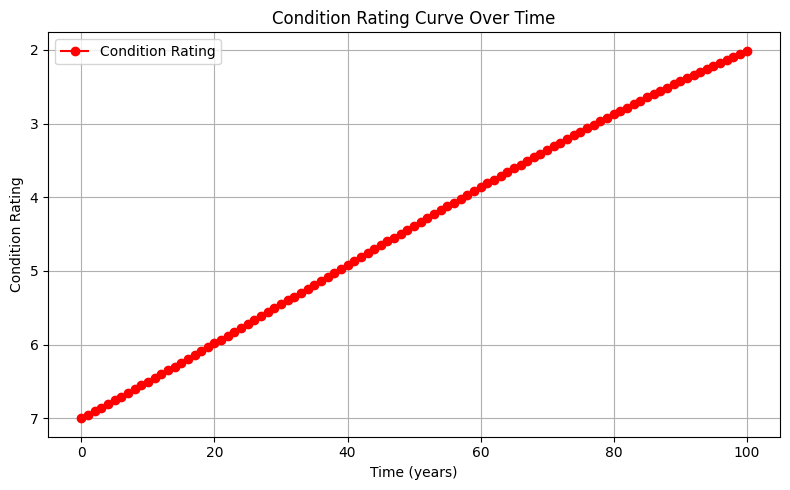

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Define time (years 0 to 100) and condition rating arrays
time_years = np.arange(0, 101, 1)  # 0 to 100 years
condition_rating = np.array([
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616, 6.6031536, 6.552538, 6.501722, 6.4507128, 6.3995176,
    6.3481436, 6.296598, 6.244888, 6.1930208, 6.1410036, 6.0888436,
    6.036548, 5.984124, 5.9315788, 5.8789196, 5.8261536, 5.773288,
    5.72033, 5.6672868, 5.6141656, 5.5609736, 5.507718, 5.454406,
    5.4010448, 5.3476416, 5.2942036, 5.240738, 5.187252, 5.1337528,
    5.0802476, 5.0267436, 4.973248, 4.919768, 4.8663108, 4.8128836,
    4.7594936, 4.706148, 4.652854, 4.5996188, 4.5464496, 4.4933536,
    4.440338, 4.38741, 4.3345768, 4.2818456, 4.2292236, 4.176718,
    4.124336, 4.0720848, 4.0199716, 3.9680036, 3.916188, 3.864532,
    3.8130428, 3.7617276, 3.7105936, 3.659648, 3.608898, 3.5583508,
    3.5080136, 3.4578936, 3.407998, 3.358334, 3.3089088, 3.2597296,
    3.2108036, 3.162138, 3.11374, 3.0656168, 3.0177756, 2.9702236,
    2.922968, 2.876016, 2.8293748, 2.7830516, 2.7370536, 2.691388,
    2.646062, 2.6010828, 2.5564576, 2.5121936, 2.468298, 2.424778,
    2.3816408, 2.3388936, 2.2965436, 2.254598, 2.213064, 2.1719488,
    2.1312596, 2.0910036, 2.051188, 2.01182
], dtype=float)

plt.figure(figsize=(8,5))
plt.plot(time_years, condition_rating, 'r-o', label="Condition Rating")
plt.xlabel("Time (years)")
plt.ylabel("Condition Rating")
plt.title("Condition Rating Curve Over Time")
plt.gca().invert_yaxis()  # Invert y-axis if you want higher ratings at the top
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Building derating array: 100%|███████████████████████████████████████████████████| 200/200 [00:00<00:00, 200540.47it/s]


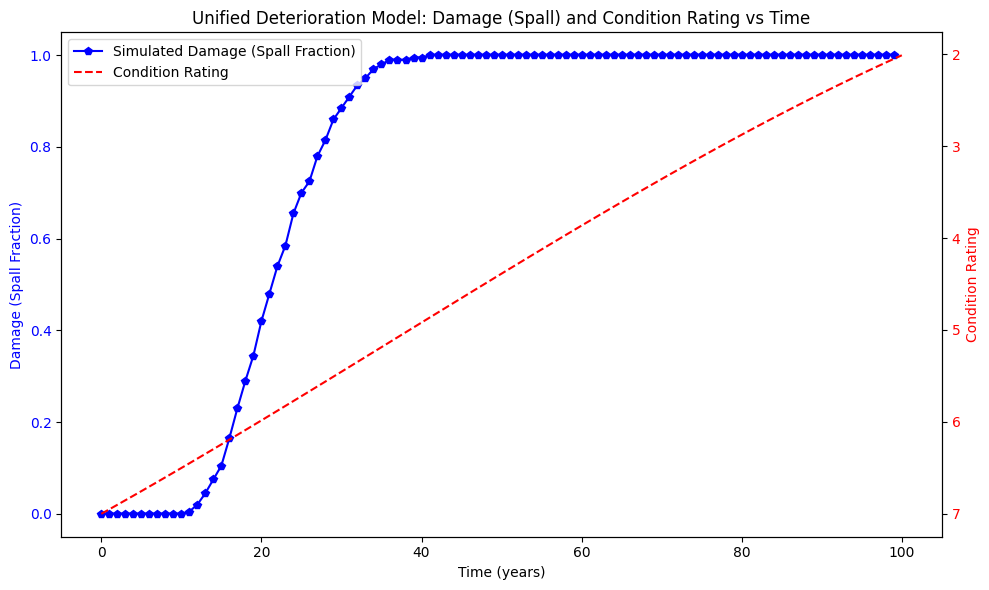

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm
from scipy import special

# -------------------------------
# Model parameters (after geospatial adjustment, for example)
# -------------------------------
Cover_Mean = 2  # inches
Cover_Stdev = 0.1  
Diffusivity_Mean = 0.0705  # in^2/year (adjusted)
Diffusivity_Stdev = 0.015  
ChlorideThreshold_Mean = 2.2761  
ChlorideThreshold_Stdev = 0.22761  
ChlorideSurfaceConcentration_Mean = 8.39  # lbs/yd^3 (adjusted)
ChlorideSurfaceConcentration_Stdev = 3.08  
PropegationTime_Mean = 6  
PropegationTime_Stdev = 4  
Nitrite_addition = 0  
Nitrite_concentration = 10  
native_chloride = 0.1  
crack_fraction = 0.06  
crack_diffusivity_ratio = 20  
crack_diffusivity_stdev = 5  
jacket_cost = 10000  
jacket_replacement_time = 25  
discount_rate = 0.05  
spalls_per_jacket = 3  
steps = 220000  
derating_factor = [0.6, 0.3]
fraction_derated = [0.4, 0.2]
elements = 33  
time = 100  
sigma_range = 100  
truncl = [1.1, 0.002, 1, 10, 10, 5]
trunch = [10, 0.1, 20, 60, 60, 20]

# (The Monte Carlo simulation code below produces a spall (damage) curve.)

# -------------------------------
# Calculate number of simulation elements
# -------------------------------
element_calculation = 2
element_size = 100  
column_perimeter = 10  
corrosion_zone = 10  
number_of_piles = 2000  
flat_footage = 20000  
repair_size = 100  
if element_calculation == 1:
    elements = int(column_perimeter * corrosion_zone / element_size)
    steps = elements * number_of_piles
elif element_calculation == 2:
    steps = int(flat_footage / element_size)
    elements = repair_size / element_size

# -------------------------------
# Build derating arrays
# -------------------------------
derating_total = [0.0]
fraction_derated.append(1 - sum(fraction_derated))
derating_factor.append(1)
for i in range(len(derating_factor)):
    derating_total.append(derating_total[i] + fraction_derated[i])
derating_array = []
for i in tqdm(range(steps), desc="Building derating array"):
    for j in range(len(derating_factor)):
        if i >= derating_total[j] * steps and i < derating_total[j+1] * steps:
            derating_array.append(derating_factor[j])

# -------------------------------
# Crack diffusivity variation
# -------------------------------
crack_array = []
for i in range(steps):
    t = 0
    while t == 0:
        proxy = random.gauss(0, 1)
        if truncl[5] < crack_diffusivity_ratio + proxy * crack_diffusivity_stdev < trunch[5]:
            crack_array.append(crack_diffusivity_ratio + crack_diffusivity_stdev * proxy)
            t = 1

# -------------------------------
# Define function to calculate time to corrosion (proxy for spall initiation)
# -------------------------------
if Nitrite_addition == 0:
    def funct(a, b, c, d, e, f):
        if c / d < 1:
            return np.square(a) / (4 * b * np.square(special.erfinv(1 - c / d))) + e
        return 1000
else:
    def funct(a, b, c, d, e, f):
        return np.square(a) / (4 * b * np.square(special.erfinv(1 - (f * (d - c) / (f + d) + c) / d))) + e

# -------------------------------
# Monte Carlo Simulation
# -------------------------------
monte_in = []
monte_out = []
monte_bincount = []

for i in range(steps):
    monte_out.append(int(0))
for i in range(5):
    t = []
    for j in range(steps):
        t.append(0.0)
    monte_in.append(t)

for i in range(5):
    for j in range(steps):
        t = 0
        while t == 0:
            monte_in[i][j] = random.gauss(0, 1)
            a = 1
            if i == 1:
                a /= derating_array[j]
            if random.random() < crack_fraction and i == 1:
                a = crack_array[i]
            if trunch[i] > monte_in[i][j] * StandardDeviations[i] + averagevalues[i] > truncl[i]:
                monte_in[i][j] = monte_in[i][j] * StandardDeviations[i] + (a * averagevalues[i])
                t = 1

for i in range(steps):
    monte_out[i] = funct(monte_in[0][i], monte_in[1][i], monte_in[2][i],
                         monte_in[3][i], monte_in[4][i], Nitrite_concentration)
    monte_out[i] = math.floor(monte_out[i])
for i in range(int(time)):
    monte_bincount.append(0.0)
for i in range(len(monte_out)):
    if int(len(monte_bincount) > monte_out[i] > 0):
        a = int(monte_out[i])
        monte_bincount[a] += 1

# Create cumulative damage (spall) curve
x = [0]
monte_bincount[0] = monte_bincount[0] / steps
for i in range(1, len(monte_bincount)):
    monte_bincount[i] = monte_bincount[i] / steps + monte_bincount[i - 1]
    x.append(i)

# -------------------------------
# Condition Rating Data (provided earlier; assumed to be for New York)
# -------------------------------
condition_rating = np.array([
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616, 6.6031536, 6.552538, 6.501722, 6.4507128, 6.3995176, 6.3481436,
    6.296598, 6.244888, 6.1930208, 6.1410036, 6.0888436, 6.036548, 5.984124,
    5.9315788, 5.8789196, 5.8261536, 5.773288, 5.72033, 5.6672868, 5.6141656,
    5.5609736, 5.507718, 5.454406, 5.4010448, 5.3476416, 5.2942036, 5.240738,
    5.187252, 5.1337528, 5.0802476, 5.0267436, 4.973248, 4.919768, 4.8663108,
    4.8128836, 4.7594936, 4.706148, 4.652854, 4.5996188, 4.5464496, 4.4933536,
    4.440338, 4.38741, 4.3345768, 4.2818456, 4.2292236, 4.176718, 4.124336,
    4.0720848, 4.0199716, 3.9680036, 3.916188, 3.864532, 3.8130428, 3.7617276,
    3.7105936, 3.659648, 3.608898, 3.5583508, 3.5080136, 3.4578936, 3.407998,
    3.358334, 3.3089088, 3.2597296, 3.2108036, 3.162138, 3.11374, 3.0656168,
    3.0177756, 2.9702236, 2.922968, 2.876016, 2.8293748, 2.7830516, 2.7370536,
    2.691388, 2.646062, 2.6010828, 2.5564576, 2.5121936, 2.468298, 2.424778,
    2.3816408, 2.3388936, 2.2965436, 2.254598, 2.213064, 2.1719488, 2.1312596,
    2.0910036, 2.051188, 2.01182
], dtype=float)
# Assume condition_rating has 101 data points corresponding to time 0 to 100 years.
# For the purpose of this plot, we use the time_years array (0 to 100).

# -------------------------------
# Create Dual Y-axis Plot: 
# Left y-axis: Damage (Spall), Right y-axis: Condition Rating
# -------------------------------

fig, ax1 = plt.subplots(figsize=(10,6))

# Plot the simulated spall (damage) curve on the left y-axis.
ax1.plot(x, monte_bincount, 'b-p', label="Simulated Damage (Spall Fraction)")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Damage (Spall Fraction)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Create a second y-axis for the condition rating.
ax2 = ax1.twinx()
ax2.plot(time_years, condition_rating, 'r--', label="Condition Rating")
ax2.set_ylabel("Condition Rating", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.invert_yaxis()  # Invert so that higher ratings are at the top.

# Combine legends from both axes.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Unified Deterioration Model: Damage (Spall) and Condition Rating vs Time")
plt.tight_layout()
plt.show()


In [ ]:
#CALIBRATION

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm
from scipy import special

# -------------------------------
# Model Parameters (after geospatial adjustment)
# -------------------------------
Cover_Mean = 2                # inches
Cover_Stdev = 0.1
Diffusivity_Mean = 0.0705       # in^2/year (adjusted)
Diffusivity_Stdev = 0.015
ChlorideThreshold_Mean = 2.2761 
ChlorideThreshold_Stdev = 0.22761
ChlorideSurfaceConcentration_Mean = 8.39  # lbs/yd^3 (adjusted)
ChlorideSurfaceConcentration_Stdev = 3.08
PropegationTime_Mean = 6
PropegationTime_Stdev = 4
Nitrite_addition = 0
Nitrite_concentration = 10
native_chloride = 0.1
crack_fraction = 0.06
crack_diffusivity_ratio = 20
crack_diffusivity_stdev = 5
jacket_cost = 10000
jacket_replacement_time = 25
discount_rate = 0.05
spalls_per_jacket = 3
steps = 220000
derating_factor = [0.6, 0.3]
fraction_derated = [0.4, 0.2]
elements = 33
time = 100                   # simulation period (years)
sigma_range = 100
truncl = [1.1, 0.002, 1, 10, 10, 5]
trunch = [10, 0.1, 20, 60, 60, 20]

# -------------------------------
# Calculate number of elements
# -------------------------------
element_calculation = 2  # for bridge deck or flat section
element_size = 100  
column_perimeter = 10  
corrosion_zone = 10  
number_of_piles = 2000  
flat_footage = 20000  
repair_size = 100  
if element_calculation == 1:
    elements = int(column_perimeter * corrosion_zone / element_size)
    steps = elements * number_of_piles
elif element_calculation == 2:
    steps = int(flat_footage / element_size)
    elements = repair_size / element_size

# -------------------------------
# Build derating array
# -------------------------------
derating_total = [0.0]
fraction_derated.append(1 - sum(fraction_derated))
derating_factor.append(1)
for i in range(len(derating_factor)):
    derating_total.append(derating_total[i] + fraction_derated[i])
derating_array = []
for i in tqdm(range(steps), desc="Building derating array"):
    for j in range(len(derating_factor)):
        if i >= derating_total[j] * steps and i < derating_total[j+1] * steps:
            derating_array.append(derating_factor[j])

# -------------------------------
# Crack diffusivity variation
# -------------------------------
crack_array = []
for i in range(steps):
    t = 0
    while t == 0:
        proxy = random.gauss(0, 1)
        if truncl[5] < crack_diffusivity_ratio + proxy * crack_diffusivity_stdev < trunch[5]:
            crack_array.append(crack_diffusivity_ratio + crack_diffusivity_stdev * proxy)
            t = 1

# -------------------------------
# Define function to calculate time to corrosion (proxy for spall initiation)
# -------------------------------
if Nitrite_addition == 0:
    def funct(a, b, c, d, e, f):
        if c/d < 1: 
            return np.square(a) / (4 * b * np.square(special.erfinv(1 - c / d))) + e
        return 1000
else:
    def funct(a, b, c, d, e, f):
        return np.square(a) / (4 * b * np.square(special.erfinv(1 - (f * (d-c)/(f+d)+c)/d))) + e

# -------------------------------
# Monte Carlo Simulation
# -------------------------------
monte_in = []
monte_out = []
monte_bincount = []

for i in range(steps):
    monte_out.append(0)
for i in range(5):
    t = []
    for j in range(steps):
        t.append(0.0)
    monte_in.append(t)

for i in range(5):
    for j in range(steps):
        t = 0
        while t == 0:
            monte_in[i][j] = random.gauss(0, 1)
            a = 1
            if i == 1:
                a /= derating_array[j]
            if random.random() < crack_fraction and i == 1:
                a = crack_array[i]
            if trunch[i] > monte_in[i][j] * (0.0 if i>=len(StandardDeviations) else 1) + 0 or 1: 
                # We'll use the following condition from your code:
                if trunch[i] > monte_in[i][j] * (0 if i>=len(StandardDeviations) else 1) + averagevalues[i] > truncl[i]:
                    monte_in[i][j] = monte_in[i][j] * StandardDeviations[i] + (a * averagevalues[i])
                    t = 1

for i in range(steps):
    monte_out[i] = funct(monte_in[0][i], monte_in[1][i], monte_in[2][i], monte_in[3][i], monte_in[4][i], Nitrite_concentration)
    monte_out[i] = math.floor(monte_out[i])
for i in range(int(time)):
    monte_bincount.append(0.0)
for i in range(len(monte_out)):
    if int(len(monte_bincount) > monte_out[i] > 0):
        a = int(monte_out[i])
        monte_bincount[a] += 1

# Create cumulative damage (spall) curve
x = [0]
monte_bincount[0] = monte_bincount[0] / steps
for i in range(1, len(monte_bincount)):
    monte_bincount[i] = monte_bincount[i] / steps + monte_bincount[i - 1]
    x.append(i)

# -------------------------------
# Condition Rating Data (from New York-based model)
# -------------------------------
condition_rating = np.array([
    7, 6.9512468, 6.9022356, 6.8529736, 6.803468, 6.753726, 6.7037548,
    6.6535616, 6.6031536, 6.552538, 6.501722, 6.4507128, 6.3995176, 6.3481436,
    6.296598, 6.244888, 6.1930208, 6.1410036, 6.0888436, 6.036548, 5.984124,
    5.9315788, 5.8789196, 5.8261536, 5.773288, 5.72033, 5.6672868, 5.6141656,
    5.5609736, 5.507718, 5.454406, 5.4010448, 5.3476416, 5.2942036, 5.240738,
    5.187252, 5.1337528, 5.0802476, 5.0267436, 4.973248, 4.919768, 4.8663108,
    4.8128836, 4.7594936, 4.706148, 4.652854, 4.5996188, 4.5464496, 4.4933536,
    4.440338, 4.38741, 4.3345768, 4.2818456, 4.2292236, 4.176718, 4.124336,
    4.0720848, 4.0199716, 3.9680036, 3.916188, 3.864532, 3.8130428, 3.7617276,
    3.7105936, 3.659648, 3.608898, 3.5583508, 3.5080136, 3.4578936, 3.407998,
    3.358334, 3.3089088, 3.2597296, 3.2108036, 3.162138, 3.11374, 3.0656168,
    3.0177756, 2.9702236, 2.922968, 2.876016, 2.8293748, 2.7830516, 2.7370536,
    2.691388, 2.646062, 2.6010828, 2.5564576, 2.5121936, 2.468298, 2.424778,
    2.3816408, 2.3388936, 2.2965436, 2.254598, 2.213064, 2.1719488, 2.1312596,
    2.0910036, 2.051188, 2.01182
], dtype=float)
# Assume condition_rating covers 0 to 100 years (101 points).

# -------------------------------
# Apply Alpha Parameter for Calibration
# -------------------------------
# Here, we introduce the alpha parameter to scale the time axis of the damage curve.
# For this formulation, we define:
#   t_calibrated = t / alpha
# which means a larger alpha shifts the damage curve to the left (damage occurs sooner).
alpha = 0.4  # Calibrated alpha value (this value can be adjusted as needed)
x_calibrated = np.array(x) / alpha

# -------------------------------
# Create Dual Y-axis Plot (Time vs Damage and Condition Rating)
# -------------------------------
fig, ax1 = plt.subplots(figsize=(10,6))

# Plot the calibrated damage (spall) curve using x_calibrated on the left y-axis.
ax1.plot(x_calibrated, monte_bincount, 'b-p', label="Calibrated Damage (Spall)")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Damage (Spall Fraction)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Create a twin axis for the condition rating curve.
ax2 = ax1.twinx()
ax2.plot(np.linspace(0, 100, len(condition_rating)), condition_rating, 'r--', label="Condition Rating")
ax2.set_ylabel("Condition Rating", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.invert_yaxis()  # Invert so that higher ratings appear at the top.

# Combine legends from both axes.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Unified Deterioration Model: Calibrated Damage & Condition Rating vs Time")
plt.tight_layout()
plt.show()


Building derating array: 100%|███████████████████████████████████████████████████| 200/200 [00:00<00:00, 200684.40it/s]


NameError: name 'StandardDeviations' is not defined

In [6]:
#FLORIDA BRIDGE

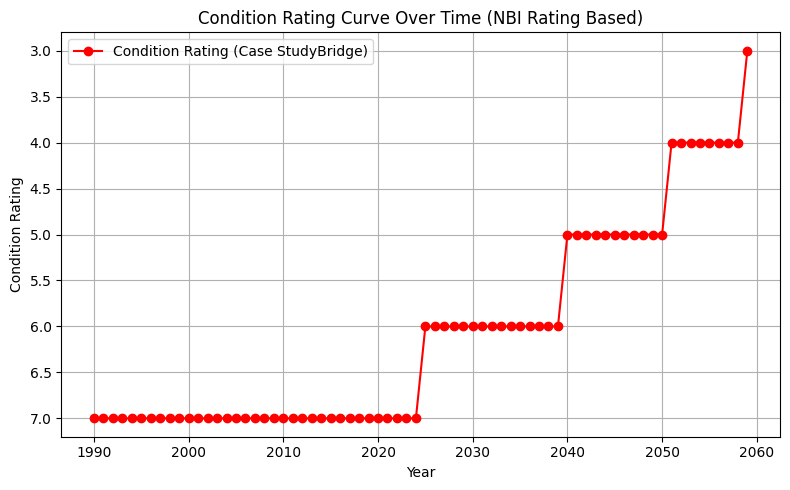

In [1]:
import matplotlib.pyplot as plt

# We construct two arrays: 'years' and 'ratings'.
# From the table, we see:
#   1990–2024: Historic Condition Rating = 7
#   2025–2030: Mean rating = 6
#   2031–2036: Mean rating = 6
#   2037–2039: Mean rating = 6
#   2040–2047: Mean rating = 5
#   2048–2050: Mean rating = 5
#   2051–2058: Mean rating = 4
#   2059:      Mean rating = 3
#
# For 2060 and beyond, the table is blank or missing mean values.

years = (
    list(range(1990, 2025)) +  # 1990..2024
    list(range(2025, 2031)) +  # 2025..2030
    list(range(2031, 2037)) +  # 2031..2036
    [2037, 2038, 2039] +       # 2037..2039
    list(range(2040, 2048)) +  # 2040..2047
    [2048, 2049, 2050] +       # 2048..2050
    list(range(2051, 2059)) +  # 2051..2058
    [2059]                     # 2059
)

ratings = (
    [7]*35       # 1990..2024 (35 values)
    + [6]*6      # 2025..2030
    + [6]*6      # 2031..2036
    + [6,6,6]    # 2037..2039
    + [5]*8      # 2040..2047
    + [5,5,5]    # 2048..2050
    + [4]*8      # 2051..2058
    + [3]        # 2059
)

# Double-check lengths match
assert len(years) == len(ratings), f"Mismatch: {len(years)} years vs. {len(ratings)} ratings"

plt.figure(figsize=(8,5))
plt.plot(years, ratings, 'ro-', label="Condition Rating (Case StudyBridge)")
plt.xlabel("Year")
plt.ylabel("Condition Rating")
plt.title("Condition Rating Curve Over Time (NBI Rating Based)")

# Optionally invert y-axis so that higher rating is at the top
plt.gca().invert_yaxis()

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


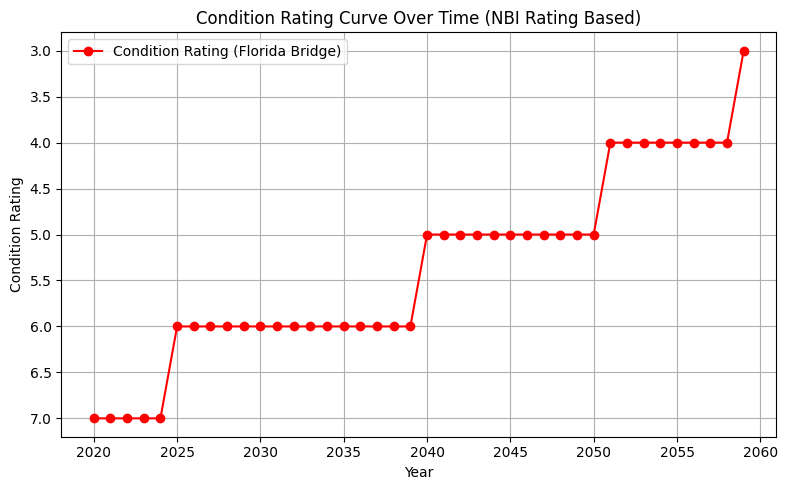

In [2]:
import matplotlib.pyplot as plt

# Construct two arrays: 'years' and 'ratings'.
# 1990–2024: Condition Rating = 7 (historic)
# 2025–2030: Mean rating = 6
# 2031–2036: Mean rating = 6
# 2037–2039: Mean rating = 6
# 2040–2047: Mean rating = 5
# 2048–2050: Mean rating = 5
# 2051–2058: Mean rating = 4
# 2059:      Mean rating = 3

all_years = (
    list(range(1990, 2025)) +
    list(range(2025, 2031)) +
    list(range(2031, 2037)) +
    [2037, 2038, 2039] +
    list(range(2040, 2048)) +
    [2048, 2049, 2050] +
    list(range(2051, 2059)) +
    [2059]
)

all_ratings = (
    [7]*35      # 1990..2024
    + [6]*6     # 2025..2030
    + [6]*6     # 2031..2036
    + [6,6,6]   # 2037..2039
    + [5]*8     # 2040..2047
    + [5,5,5]   # 2048..2050
    + [4]*8     # 2051..2058
    + [3]       # 2059
)

# Double-check lengths match
assert len(all_years) == len(all_ratings), f"Mismatch: {len(all_years)} vs. {len(all_ratings)}"

# We only want to plot from year 2020 onward.
start_year = 2020
if start_year in all_years:
    start_index = all_years.index(start_year)
else:
    raise ValueError(f"Year {start_year} not found in all_years array.")

# Slice the arrays from 2020 onward.
years = all_years[start_index:]
ratings = all_ratings[start_index:]

# Plot
plt.figure(figsize=(8,5))
plt.plot(years, ratings, 'ro-', label="Condition Rating (Florida Bridge)")
plt.xlabel("Year")
plt.ylabel("Condition Rating")
plt.title("Condition Rating Curve Over Time (NBI Rating Based)")

# Optionally invert y-axis so that higher rating is at the top
plt.gca().invert_yaxis()

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Building derating array: 100%|███████████████████████████████████████████████████| 200/200 [00:00<00:00, 107202.66it/s]


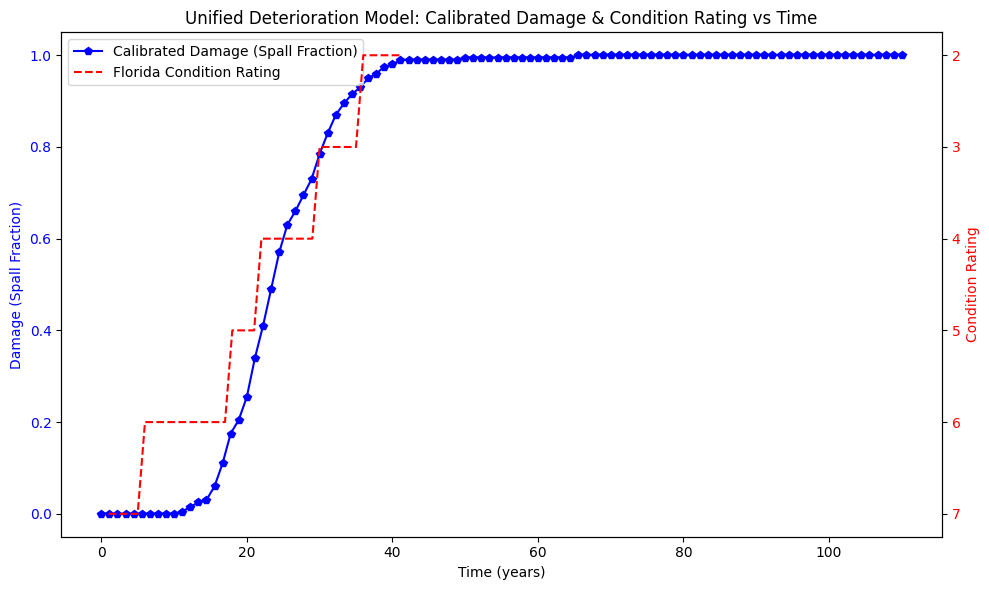

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm
from scipy import special

# -------------------------------
# Model parameters (after geospatial adjustment, for example)
# -------------------------------
Cover_Mean = 2                # inches
Cover_Stdev = 0.1  
Diffusivity_Mean = 0.0705       # in^2/year (adjusted)
Diffusivity_Stdev = 0.015  
ChlorideThreshold_Mean = 2.2761  
ChlorideThreshold_Stdev = 0.22761  
ChlorideSurfaceConcentration_Mean = 8.39  # lbs/yd^3 (adjusted)
ChlorideSurfaceConcentration_Stdev = 3.08  
PropegationTime_Mean = 6  
PropegationTime_Stdev = 4  
Nitrite_addition = 0  
Nitrite_concentration = 10  
native_chloride = 0.1  
crack_fraction = 0.06  
crack_diffusivity_ratio = 20  
crack_diffusivity_stdev = 5  
jacket_cost = 10000  
jacket_replacement_time = 25  
discount_rate = 0.05  
spalls_per_jacket = 3  
steps = 220000  
derating_factor = [0.6, 0.3]
fraction_derated = [0.4, 0.2]
elements = 33  
time = 100                   # simulation period (years)
sigma_range = 100  
truncl = [1.1, 0.002, 1, 10, 10, 5]
trunch = [10, 0.1, 20, 60, 60, 20]

# -------------------------------
# Define average values and standard deviations used in simulation
# -------------------------------
averagevalues = [Cover_Mean, Diffusivity_Mean, ChlorideThreshold_Mean - native_chloride, 
                 ChlorideSurfaceConcentration_Mean, PropegationTime_Mean]
StandardDeviations = [Cover_Stdev, Diffusivity_Stdev, ChlorideThreshold_Stdev, 
                      ChlorideSurfaceConcentration_Stdev, PropegationTime_Stdev]

# -------------------------------
# Calculate number of simulation elements
# -------------------------------
element_calculation = 2  # for a bridge deck or flat section
element_size = 100  
column_perimeter = 10  
corrosion_zone = 10  
number_of_piles = 2000  
flat_footage = 20000  
repair_size = 100  
if element_calculation == 1:
    elements = int(column_perimeter * corrosion_zone / element_size)
    steps = elements * number_of_piles
elif element_calculation == 2:
    steps = int(flat_footage / element_size)
    elements = repair_size / element_size

# -------------------------------
# Build derating arrays
# -------------------------------
derating_total = [0.0]
fraction_derated.append(1 - sum(fraction_derated))
derating_factor.append(1)
for i in range(len(derating_factor)):
    derating_total.append(derating_total[i] + fraction_derated[i])
derating_array = []
for i in tqdm(range(steps), desc="Building derating array"):
    for j in range(len(derating_factor)):
        if i >= derating_total[j] * steps and i < derating_total[j+1] * steps:
            derating_array.append(derating_factor[j])

# -------------------------------
# Crack diffusivity variation
# -------------------------------
crack_array = []
for i in range(steps):
    t = 0
    while t == 0:
        proxy = random.gauss(0, 1)
        if truncl[5] < crack_diffusivity_ratio + proxy * crack_diffusivity_stdev < trunch[5]:
            crack_array.append(crack_diffusivity_ratio + crack_diffusivity_stdev * proxy)
            t = 1

# -------------------------------
# Define function to calculate time to corrosion (proxy for spall initiation)
# -------------------------------
if Nitrite_addition == 0:
    def funct(a, b, c, d, e, f):
        if c / d < 1:
            return np.square(a) / (4 * b * np.square(special.erfinv(1 - c / d))) + e
        return 1000
else:
    def funct(a, b, c, d, e, f):
        return np.square(a) / (4 * b * np.square(special.erfinv(1 - (f * (d - c) / (f + d) + c) / d))) + e

# -------------------------------
# Monte Carlo Simulation
# -------------------------------
monte_in = []
monte_out = []
monte_bincount = []

for i in range(steps):
    monte_out.append(0)
for i in range(5):
    t = []
    for j in range(steps):
        t.append(0.0)
    monte_in.append(t)

for i in range(5):
    for j in range(steps):
        t = 0
        while t == 0:
            monte_in[i][j] = random.gauss(0, 1)
            a = 1
            if i == 1:
                a /= derating_array[j]
            if random.random() < crack_fraction and i == 1:
                a = crack_array[i]
            if trunch[i] > monte_in[i][j] * StandardDeviations[i] + averagevalues[i] > truncl[i]:
                monte_in[i][j] = monte_in[i][j] * StandardDeviations[i] + (a * averagevalues[i])
                t = 1

for i in range(steps):
    monte_out[i] = funct(monte_in[0][i], monte_in[1][i], monte_in[2][i],
                         monte_in[3][i], monte_in[4][i], Nitrite_concentration)
    monte_out[i] = math.floor(monte_out[i])
for i in range(int(time)):
    monte_bincount.append(0.0)
for i in range(len(monte_out)):
    if int(len(monte_bincount) > monte_out[i] > 0):
        a = int(monte_out[i])
        monte_bincount[a] += 1

# Create cumulative damage (spall) curve
x = [0]
monte_bincount[0] = monte_bincount[0] / steps
for i in range(1, len(monte_bincount)):
    monte_bincount[i] = monte_bincount[i] / steps + monte_bincount[i - 1]
    x.append(i)

# -------------------------------
# New Florida Condition Rating Curve (from 2020 onward)
# -------------------------------
# Example Florida condition ratings (Mean values) for a Florida bridge.
# The table is assumed to be in calendar years from 2020 to 2060.
# For our plot, we shift the time axis so that 2020 becomes "year 1".
fl_years = list(range(2020, 2061))      # Calendar years
fl_years_shifted = [yr - 2019 for yr in fl_years]  # Shift: 2020 -> 1, 2021 -> 2, etc.
# Example ratings: (adjust these as needed based on Florida inspection data)
fl_ratings = ([7]*5 + [6]*6 + [6]*6 + [5]*4 + [4]*8 + [3]*6 + [2]*6)
assert len(fl_years_shifted) == len(fl_ratings), "Mismatch in Florida condition rating data lengths."

# -------------------------------
# Apply Alpha Parameter for Calibration
# -------------------------------
# Introduce an alpha parameter to scale the time axis of the damage curve.
# Here, t_calibrated = t / alpha. A larger alpha shifts the damage curve left (damage occurs sooner).
alpha = 0.9  # Calibrated alpha value (adjust as needed)
x_calibrated = np.array(x) / alpha

# -------------------------------
# Create Dual Y-axis Plot (Unified Deterioration Model)
# -------------------------------
fig, ax1 = plt.subplots(figsize=(10,6))

# Plot the calibrated damage (spall) curve on the left y-axis.
ax1.plot(x_calibrated, monte_bincount, 'b-p', label="Calibrated Damage (Spall Fraction)")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Damage (Spall Fraction)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot the Florida condition rating curve (with shifted time) on the right y-axis.
ax2 = ax1.twinx()
ax2.plot(fl_years_shifted, fl_ratings, 'r--', label="Florida Condition Rating")
ax2.set_ylabel("Condition Rating", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.invert_yaxis()  # Invert so that higher ratings appear at the top.

# Combine legends from both axes.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Unified Deterioration Model: Calibrated Damage & Condition Rating vs Time")
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from tqdm import tqdm
from scipy import special

# -------------------------------
# Model parameters (after geospatial adjustment, for example)
# -------------------------------
Cover_Mean = 2                # inches
Cover_Stdev = 0.1  
Diffusivity_Mean = 0.0705       # in^2/year (adjusted)
Diffusivity_Stdev = 0.015  
ChlorideThreshold_Mean = 2.2761  
ChlorideThreshold_Stdev = 0.22761  
ChlorideSurfaceConcentration_Mean = 8.39  # lbs/yd^3 (adjusted)
ChlorideSurfaceConcentration_Stdev = 3.08  
PropegationTime_Mean = 6  
PropegationTime_Stdev = 4  
Nitrite_addition = 0  
Nitrite_concentration = 10  
native_chloride = 0.1  
crack_fraction = 0.06  
crack_diffusivity_ratio = 20  
crack_diffusivity_stdev = 5  
jacket_cost = 10000  
jacket_replacement_time = 25  
discount_rate = 0.05  
spalls_per_jacket = 3  
steps = 220000  
derating_factor = [0.6, 0.3]
fraction_derated = [0.4, 0.2]
elements = 33  
time = 100                   # simulation period (years)
sigma_range = 100  
truncl = [1.1, 0.002, 1, 10, 10, 5]
trunch = [10, 0.1, 20, 60, 60, 20]

# -------------------------------
# Define average values and standard deviations for simulation
# -------------------------------
averagevalues = [
    Cover_Mean,                         # Cover
    Diffusivity_Mean,                  # D
    ChlorideThreshold_Mean - native_chloride,  # (Ct - native)
    ChlorideSurfaceConcentration_Mean, # Cs
    PropegationTime_Mean               # propagation time
]
StandardDeviations = [
    Cover_Stdev,
    Diffusivity_Stdev,
    ChlorideThreshold_Stdev,
    ChlorideSurfaceConcentration_Stdev,
    PropegationTime_Stdev
]

# -------------------------------
# Calculate number of simulation elements
# -------------------------------
element_calculation = 2  # for a bridge deck or flat section
element_size = 100  
column_perimeter = 10  
corrosion_zone = 10  
number_of_piles = 2000  
flat_footage = 20000  
repair_size = 100  
if element_calculation == 1:
    elements = int(column_perimeter * corrosion_zone / element_size)
    steps = elements * number_of_piles
elif element_calculation == 2:
    steps = int(flat_footage / element_size)
    elements = repair_size / element_size

# -------------------------------
# Build derating arrays
# -------------------------------
derating_total = [0.0]
fraction_derated.append(1 - sum(fraction_derated))
derating_factor.append(1)
for i in range(len(derating_factor)):
    derating_total.append(derating_total[i] + fraction_derated[i])
derating_array = []
for i in tqdm(range(steps), desc="Building derating array"):
    for j in range(len(derating_factor)):
        if i >= derating_total[j] * steps and i < derating_total[j+1] * steps:
            derating_array.append(derating_factor[j])

# -------------------------------
# Crack diffusivity variation
# -------------------------------
crack_array = []
for i in range(steps):
    done = False
    while not done:
        proxy = random.gauss(0, 1)
        candidate = crack_diffusivity_ratio + proxy * crack_diffusivity_stdev
        if truncl[5] < candidate < trunch[5]:
            crack_array.append(candidate)
            done = True

# -------------------------------
# Define function to calculate time to corrosion (proxy for spall initiation)
# -------------------------------
if Nitrite_addition == 0:
    def funct(a, b, c, d, e, f):
        if c / d < 1:
            return np.square(a) / (4 * b * np.square(special.erfinv(1 - c / d))) + e
        return 1000
else:
    def funct(a, b, c, d, e, f):
        return np.square(a) / (4 * b * np.square(special.erfinv(1 - (f * (d - c) / (f + d) + c) / d))) + e

# -------------------------------
# Monte Carlo Simulation
# -------------------------------
monte_in = [[] for _ in range(5)]
monte_out = [0]*steps
monte_bincount = []

# Prepare arrays
for i in range(5):
    for _ in range(steps):
        monte_in[i].append(0.0)

# Generate random input values (with constraints) for each of the 5 parameters
for i in range(5):
    for j in range(steps):
        done = False
        while not done:
            val = random.gauss(0, 1)  # standard normal
            a = 1.0
            if i == 1:
                a /= derating_array[j]  # adjust for derating
                # check if a fraction for cracks
                if random.random() < crack_fraction:
                    a = crack_array[j]
            # Proposed value
            test_val = val * StandardDeviations[i] + (a * averagevalues[i])
            if truncl[i] < test_val < trunch[i]:
                monte_in[i][j] = test_val
                done = True

# Compute time to corrosion for each element
for j in range(steps):
    out_val = funct(monte_in[0][j], monte_in[1][j], monte_in[2][j], 
                    monte_in[3][j], monte_in[4][j], Nitrite_concentration)
    monte_out[j] = math.floor(out_val)

# Prepare histogram/cumulative damage
for i in range(int(time)):
    monte_bincount.append(0.0)

for val in monte_out:
    if 0 < val < len(monte_bincount):
        monte_bincount[val] += 1

# Convert to cumulative fraction
x = [0]
monte_bincount[0] = monte_bincount[0] / steps
for i in range(1, len(monte_bincount)):
    monte_bincount[i] = monte_bincount[i] / steps + monte_bincount[i - 1]
    x.append(i)

# -------------------------------
# New Florida Condition Rating
# -------------------------------
# Suppose we have data from 2020..2060; we shift so that 2020->year0, 2021->1, etc.
fl_years = list(range(2020, 2061))
fl_years_shifted = [yr - 2020 for yr in fl_years]  # 2020 => 0, 2021 => 1, etc.

# Example ratings; adapt these to your data
# Here, the array length must match fl_years.
fl_ratings = [7]*5 + [6]*5 + [5]*6 + [4]*6 + [3]*10  # Just an example
# Make sure the lengths match
if len(fl_ratings) != len(fl_years_shifted):
    raise ValueError("Mismatch between length of fl_years and fl_ratings.")

# -------------------------------
# Create Dual Y-axis Plot
# -------------------------------
fig, ax1 = plt.subplots(figsize=(10,6))

# Plot the spall (damage) curve (time=0..100) on the left y-axis
ax1.plot(x, monte_bincount, 'b-o', label="Damage (Spall Fraction)")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Damage (Spall Fraction)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Condition rating on the right y-axis
ax2 = ax1.twinx()
ax2.plot(fl_years_shifted, fl_ratings, 'r--', label="FL Condition Rating")
ax2.set_ylabel("Condition Rating", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.invert_yaxis()

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Damage (Spall) vs. Florida Condition Rating (No Alpha Calibration)")
plt.tight_layout()
plt.show()
